# Analisis ARM dan SPM: Keterkaitan Pasar Saham Global dengan Indeks ISE (2009 sampai 2011)

**Dataset:** `data_akbilgic.xlsx` (Akbilgic, Bozdogan & Balaban, UCI Machine Learning Repository). Isinya *return* harian indeks Istanbul Stock Exchange (ISE 100, berbasis TL dan USD) beserta tujuh indeks global: S&P 500 (SP), DAX, FTSE 100, Nikkei 225, Bovespa, MSCI Europe (EU), dan MSCI Emerging Markets (EM), periode 5 Januari 2009 sampai 22 Februari 2011.

**Rumusan masalah**
1. Kombinasi kondisi pasar global apa yang sering terjadi bersamaan dengan naik atau turunnya indeks ISE pada hari yang sama?
2. Apakah kondisi pasar global pada hari sebelumnya dapat menjadi petunjuk arah ISE hari ini?
3. Urutan pergerakan antarpasar seperti apa yang sering terjadi dalam rentang beberapa hari, dan bagaimana sentimen menyebar dari satu wilayah ke wilayah lain?

| Metode | Tujuan | Menjawab |
|---|---|---|
| ARM hari yang sama | Menemukan *co-movement* antarindeks dan ISE | RM 1 |
| ARM dengan lag | Menemukan kondisi hari t-1 yang berasosiasi dengan ISE hari t | RM 2 |
| SPM | Menemukan pola penyebaran sentimen antarwilayah dalam beberapa hari | RM 3 |

**Alur notebook:** setup → pemuatan dan pemeriksaan data → EDA → preprocessing (diskretisasi dan urutan sesi perdagangan) → ARM hari yang sama → ARM lag → SPM → uji sensitivitas → jawaban rumusan masalah.

Prinsip yang dipegang: setiap aturan atau pola yang diklaim harus lolos uji statistik (bukan hanya lolos ambang support/confidence), dan klaim prediktif harus diuji pada periode data yang tidak dipakai saat mining.

## 1. Setup dan Konfigurasi
Semua parameter analisis dikumpulkan di satu tempat agar mudah diubah dan dilaporkan.

In [4]:
import warnings
warnings.filterwarnings('ignore')

from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx
from scipy.stats import fisher_exact, binomtest
from mlxtend.frequent_patterns import apriori, association_rules

pd.set_option('display.width', 200)
pd.set_option('display.max_colwidth', 70)
sns.set_theme(style='whitegrid', context='notebook')
COLOR = {'Up': '#2a9d8f', 'Down': '#e76f51', 'Flat': '#c7c7c7'}

# ---------------- Konfigurasi ----------------
DATA_PATH = '../data/data_akbilgic.xlsx'   # relatif terhadap folder notebooks/
OUTPUT_DIR = '../outputs'
SEED = 42
K_SIGMA = 0.5            # ambang diskretisasi: Up jika return > K_SIGMA*std, Down jika < -K_SIGMA*std
ALPHA = 0.05             # taraf signifikansi setelah koreksi Benjamini-Hochberg (BH)
MIN_IMPROVEMENT = 0.02   # aturan harus menaikkan confidence >= 2 poin persen dibanding aturan induknya

ARM_SAME_MINSUP, ARM_SAME_MAXLEN = 0.05, 4   # ARM hari yang sama (maks 3 antecedent + 1 target)
ARM_LAG_MINSUP,  ARM_LAG_MAXLEN  = 0.03, 3   # ARM lag (maks 2 antecedent + 1 target)

SPM_WINDOW = 3           # panjang jendela sekuens (hari bursa)
SPM_MINSUP = 0.20        # minimum support pola sekuensial (proporsi jendela)
SPM_MAX_ITEMS, SPM_MAX_ELEMS = 4, 3
N_PERM = 200             # jumlah permutasi untuk uji signifikansi pola SPM
TRAIN_FRAC = 0.70        # proporsi periode awal untuk validasi temporal

GLOBAL = ['SP', 'DAX', 'FTSE', 'NIKKEI', 'BOVESPA', 'EU', 'EM']
rng = np.random.default_rng(SEED)

## 2. Memuat Data
Baris pertama file Excel berisi keterangan `TL BASED` / `USD BASED`, sehingga header kolom yang sebenarnya ada di baris kedua (`header=1`). Dua kolom ISE diberi nama berbeda agar tidak tertukar.

In [5]:
raw = pd.read_excel(DATA_PATH, header=1)
raw.columns = ['date', 'ISE_TL', 'ISE_USD'] + GLOBAL
raw['date'] = pd.to_datetime(raw['date'])
print('Ukuran data:', raw.shape)
raw.head()

Ukuran data: (536, 10)


,date,ISE_TL,ISE_USD,SP,DAX,FTSE,NIKKEI,BOVESPA,EU,EM
0,2009-01-05,0.035754,0.038376,-0.004679,0.002193,0.003894,0.000000,0.031190,0.012698,0.028524
1,2009-01-06,0.025426,0.031813,0.007787,0.008455,0.012866,0.004162,0.018920,0.011341,0.008773
2,2009-01-07,-0.028862,-0.026353,-0.030469,-0.017833,-0.028735,0.017293,-0.035899,-0.017073,-0.020015
3,2009-01-08,-0.062208,-0.084716,0.003391,-0.011726,-0.000466,-0.040061,0.028283,-0.005561,-0.019424
4,2009-01-09,0.009860,0.009658,-0.021533,-0.019873,-0.012710,-0.004474,-0.009764,-0.010989,-0.007802


## 3. Pemeriksaan Kualitas Data
Yang diperiksa: nilai hilang, duplikasi tanggal, urutan waktu, dan return bernilai tepat nol. Return nol pada indeks non-Turki biasanya berarti bursa tersebut libur pada hari bursa Istanbul buka, sehingga harganya tidak berubah.

In [6]:
num = raw.drop(columns='date')
quality = pd.DataFrame({'missing': num.isna().sum(),
                        'return_nol': (num == 0).sum(),
                        'tipe': num.dtypes.astype(str)})
print('Duplikat tanggal :', raw['date'].duplicated().sum())
print('Tanggal terurut  :', raw['date'].is_monotonic_increasing)
print('Rentang tanggal  :', raw['date'].min().date(), 's/d', raw['date'].max().date())
bdays = pd.bdate_range(raw['date'].min(), raw['date'].max())
print('Hari kerja Senin-Jumat tanpa baris data (libur bursa Istanbul):', len(bdays.difference(raw['date'])))
quality

Duplikat tanggal : 0
Tanggal terurut  : True
Rentang tanggal  : 2009-01-05 s/d 2011-02-22
Hari kerja Senin-Jumat tanpa baris data (libur bursa Istanbul): 21


,missing,return_nol,tipe
ISE_TL,0,0,float64
ISE_USD,0,0,float64
SP,0,18,float64
DAX,0,10,float64
FTSE,0,14,float64
NIKKEI,0,34,float64
BOVESPA,0,29,float64
EU,0,5,float64
EM,0,0,float64



**Catatan kualitas data**
* Tidak ada nilai hilang, tidak ada tanggal ganda, dan tanggal sudah terurut. Data berisi 536 hari bursa.
* Ada 21 hari kerja Senin-Jumat yang tidak tercatat. Kalender dataset mengikuti hari buka bursa Istanbul, jadi hari tersebut adalah libur Turki. Karena itu ISE tidak pernah bernilai nol.
* Return nol muncul pada NIKKEI (34 hari), BOVESPA (29), SP (18), FTSE (14), DAX (10), dan EU (5), yaitu hari ketika bursa tersebut libur sementara Istanbul buka. Nilai ini **tidak diimputasi** karena memang benar tidak ada pergerakan. Setelah diskretisasi, hari tersebut otomatis masuk kategori Flat.
* Return ekstrem (misalnya ISE -6,2% dan +6,9%) tidak dibuang. Nilai itu kejadian pasar yang nyata, dan diskretisasi membuat ARM/SPM tidak sensitif terhadap besaran ekstremnya.


## 4. Exploratory Data Analysis
### 4.1 Statistik deskriptif dan distribusi return

,count,mean,std,min,25%,50%,75%,max
ISE_TL,536.0,0.0016,0.0163,-0.0622,-0.0067,0.0022,0.0106,0.0690
ISE_USD,536.0,0.0016,0.0211,-0.0847,-0.0098,0.0026,0.0138,0.1006
SP,536.0,0.0006,0.0141,-0.0543,-0.0047,0.0009,0.0067,0.0684
DAX,536.0,0.0007,0.0146,-0.0523,-0.0062,0.0009,0.0082,0.0590
FTSE,536.0,0.0005,0.0127,-0.0548,-0.0058,0.0004,0.0074,0.0503
NIKKEI,536.0,0.0003,0.0149,-0.0504,-0.0074,0.0000,0.0079,0.0612
BOVESPA,536.0,0.0009,0.0158,-0.0538,-0.0072,0.0003,0.0089,0.0638
EU,536.0,0.0005,0.0130,-0.0488,-0.0060,0.0002,0.0078,0.0670
EM,536.0,0.0009,0.0105,-0.0386,-0.0049,0.0011,0.0064,0.0478


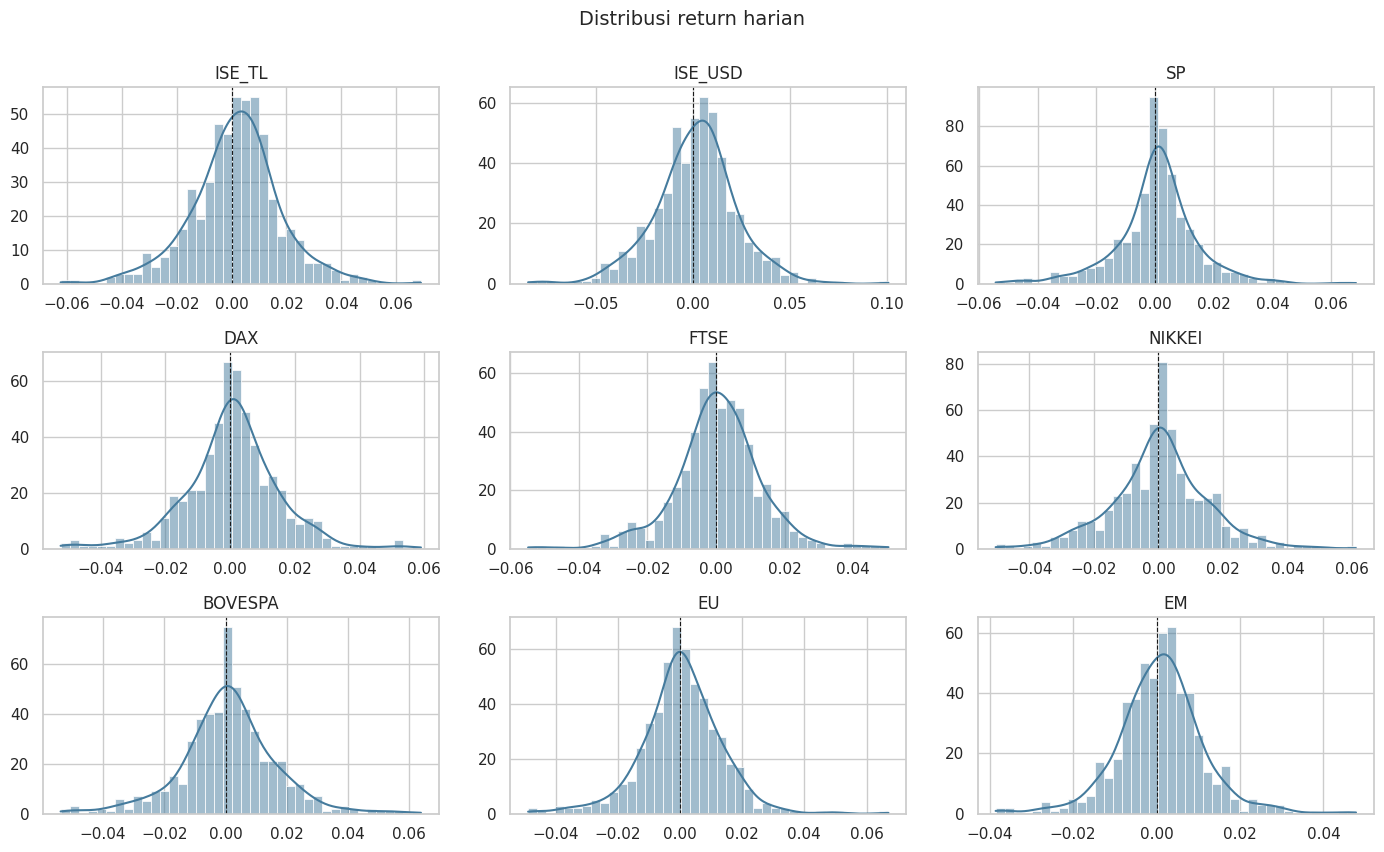

In [7]:
df = raw.set_index('date')
display(df.describe().T.round(4))

fig, axes = plt.subplots(3, 3, figsize=(14, 8.5))
for ax, c in zip(axes.flat, df.columns):
    sns.histplot(df[c], bins=40, kde=True, ax=ax, color='#457b9d')
    ax.axvline(0, color='k', lw=0.8, ls='--')
    ax.set_title(c); ax.set_xlabel(''); ax.set_ylabel('')
fig.suptitle('Distribusi return harian', y=1.0, fontsize=14)
plt.tight_layout(); plt.show()

### 4.2 Korelasi hari yang sama dan korelasi lag-1 terhadap ISE
Korelasi linear dipakai sebagai gambaran awal sebelum mining. Panel kanan menunjukkan korelasi return indeks pada hari t-1 dengan return ISE (TL) pada hari t.

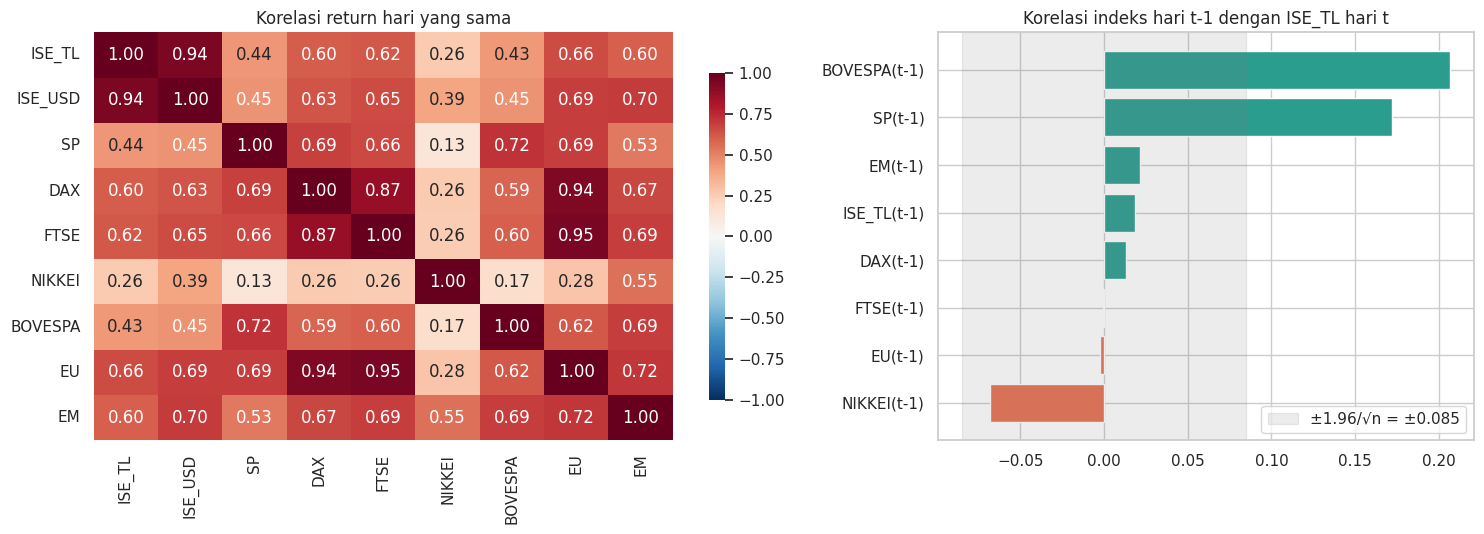

NIKKEI(t-1)    -0.068
EU(t-1)        -0.002
FTSE(t-1)      -0.000
DAX(t-1)        0.013
ISE_TL(t-1)     0.019
EM(t-1)         0.021
SP(t-1)         0.172
BOVESPA(t-1)    0.206


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), gridspec_kw={'width_ratios': [1.35, 1]})
sns.heatmap(df.corr(), annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1, ax=axes[0], cbar_kws={'shrink': .8})
axes[0].set_title('Korelasi return hari yang sama')

lag_corr = df[['ISE_TL'] + GLOBAL].shift(1).corrwith(df['ISE_TL']).rename(index={'ISE_TL': 'ISE_TL'})
lag_corr.index = [f'{c}(t-1)' for c in lag_corr.index]
lag_corr = lag_corr.sort_values()
n = len(df) - 1
ci = 1.96 / np.sqrt(n)    # batas kasar korelasi nol pada alpha 5%
axes[1].barh(lag_corr.index, lag_corr.values, color=['#e76f51' if v < 0 else '#2a9d8f' for v in lag_corr.values])
axes[1].axvspan(-ci, ci, color='grey', alpha=.15, label=f'±1.96/√n = ±{ci:.3f}')
axes[1].set_title('Korelasi indeks hari t-1 dengan ISE_TL hari t'); axes[1].legend(loc='lower right')
plt.tight_layout(); plt.show()
print(lag_corr.round(3).to_string())


**Temuan EDA**
* Pada hari yang sama, ISE paling erat bergerak dengan indeks Eropa (EU 0,66; FTSE 0,62; DAX 0,60) dan EM (0,60). Hubungan dengan Amerika lebih lemah (SP 0,44; BOVESPA 0,43), dan paling lemah dengan NIKKEI (0,26).
* DAX, FTSE, dan EU saling berkorelasi 0,87 sampai 0,95. Ketiganya membawa informasi yang hampir sama, sehingga aturan yang menggabungkan dua indeks Eropa diperkirakan redundan.
* Pada lag 1 hari, hanya **BOVESPA(t-1) (0,21) dan SP(t-1) (0,17)** yang keluar dari pita ±0,085. Indeks lain, termasuk ISE(t-1) sendiri (0,019), praktis tidak berkorelasi dengan ISE hari ini. Pola ini sesuai dengan urutan jam perdagangan pada Bagian 5.3: pasar Amerika tutup setelah Istanbul, sehingga pergerakannya baru bisa tercermin di Istanbul keesokan harinya.

Ekspektasi awal: rumusan masalah 1 akan didominasi Eropa dan EM, sedangkan rumusan masalah 2 akan menghasilkan sinyal yang jauh lebih lemah dan berasal dari Amerika.


## 5. Preprocessing
### 5.1 Pemilihan target
ISE tersedia dalam dua versi. Versi TL mengukur pergerakan harga saham Turki itu sendiri, sedangkan versi USD mencampurkan pergerakan saham dengan pergerakan kurs USD/TRY. Karena rumusan masalah menanyakan arah pasar saham Turki, **target utama adalah `ISE_TL`** (selanjutnya disebut `ISE`). `ISE_USD` dikeluarkan dari mining karena korelasinya 0,94 dengan `ISE_TL`; jika ikut dimasukkan, aturan seperti `ISE_USD↑ ⇒ ISE↑` akan mendominasi tanpa memberi informasi baru.

In [9]:
agree = (np.sign(df['ISE_TL']) == np.sign(df['ISE_USD'])).mean()
print(f'Arah ISE_TL dan ISE_USD sama pada {agree:.1%} hari')

ret = df.rename(columns={'ISE_TL': 'ISE'})[['ISE'] + GLOBAL]
ret.head(3)

Arah ISE_TL dan ISE_USD sama pada 87.3% hari


,ISE,SP,DAX,FTSE,NIKKEI,BOVESPA,EU,EM
date,,,,,,,,
2009-01-05,0.035754,-0.004679,0.002193,0.003894,0.000000,0.031190,0.012698,0.028524
2009-01-06,0.025426,0.007787,0.008455,0.012866,0.004162,0.018920,0.011341,0.008773
2009-01-07,-0.028862,-0.030469,-0.017833,-0.028735,0.017293,-0.035899,-0.017073,-0.020015


### 5.2 Diskretisasi return menjadi kondisi pasar
ARM dan SPM bekerja pada item kategorik, sehingga setiap return diubah menjadi tiga kondisi:

* **Up** jika return > K·σ, **Down** jika return < -K·σ, **Flat** jika di antaranya, dengan σ adalah simpangan baku indeks tersebut dan K = 0,5.

Ambang berbasis σ dipilih karena volatilitas tiap indeks berbeda (σ ISE sekitar 1,6% sedangkan EM sekitar 1,05%), sehingga satu ambang absolut akan tidak adil antarindeks. Ambang 0,5σ menyaring pergerakan kecil yang lebih mirip *noise* dan sekaligus menyerap hari libur (return 0) ke kategori Flat. Pengaruh pilihan K diuji ulang pada Bagian 9.

,ISE,SP,DAX,FTSE,NIKKEI,BOVESPA,EU,EM
sigma,0.0163,0.0141,0.0146,0.0127,0.0149,0.0158,0.0130,0.0105
ambang (±),0.0081,0.0070,0.0073,0.0063,0.0074,0.0079,0.0065,0.0053


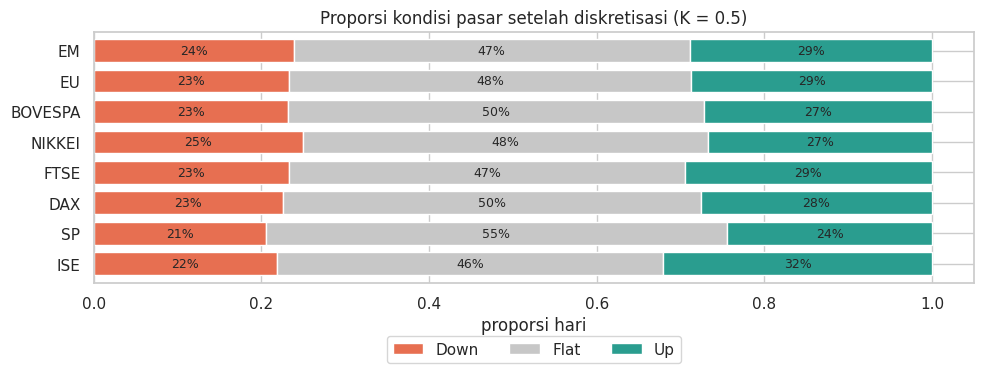

In [10]:
def discretize(returns, sigma, k=K_SIGMA):
    # Ubah return numerik menjadi 'Up' / 'Flat' / 'Down' memakai ambang k * sigma per kolom
    th = k * sigma
    lab = pd.DataFrame('Flat', index=returns.index, columns=returns.columns)
    lab[returns.gt(th)] = 'Up'
    lab[returns.lt(-th)] = 'Down'
    return lab

sigma = ret.std()
states = discretize(ret, sigma)
display(pd.DataFrame({'sigma': sigma, 'ambang (±)': K_SIGMA * sigma}).T.round(4))

dist = states.apply(lambda s: s.value_counts(normalize=True)).T[['Down', 'Flat', 'Up']]
ax = dist.plot(kind='barh', stacked=True, figsize=(10, 4), color=[COLOR[c] for c in dist.columns], width=.75)
for cont in ax.containers:
    ax.bar_label(cont, labels=[f'{v:.0%}' for v in cont.datavalues], label_type='center', fontsize=9)
ax.set_title(f'Proporsi kondisi pasar setelah diskretisasi (K = {K_SIGMA})'); ax.set_xlabel('proporsi hari')
ax.legend(ncol=3, bbox_to_anchor=(0.5, -0.18), loc='upper center'); plt.tight_layout(); plt.show()

### 5.3 Urutan sesi perdagangan (dasar untuk lag dan SPM)
Dalam satu tanggal kalender, bursa tidak tutup bersamaan. Perkiraan waktu penutupan (UTC) pada periode data:

| Sesi | Indeks | Penutupan (perkiraan) |
|---|---|---|
| S1 Asia | NIKKEI | sekitar 06:00 UTC |
| S2 Eropa dan Turki | ISE, DAX, FTSE, EU | sekitar 15:30 sampai 16:30 UTC |
| S3 Amerika dan global | SP, BOVESPA, EM | sekitar 20:00 sampai 21:00 UTC |

EM ditempatkan di S3 karena nilai penutupan harian indeks MSCI dihitung setelah semua bursa konstituennya (termasuk Brasil dan Meksiko) tutup. Konsekuensinya:
* Pada ARM hari yang sama, hubungan ISE dengan SP, BOVESPA, dan EM adalah **asosiasi**, bukan sebab-akibat, karena kedua pasar Amerika tutup setelah Istanbul.
* Return SP dan BOVESPA hari t-1 adalah informasi terbaru dari Amerika yang tersedia saat Istanbul membuka sesi hari t. Ini yang menjelaskan mengapa korelasi lag-1 hanya muncul pada dua indeks tersebut.

### 5.4 Fungsi utilitas ARM
Fungsi di bawah membentuk tabel transaksi *one-hot*, menjalankan Apriori (mlxtend), lalu menambahkan tiga lapis evaluasi pada setiap aturan `antecedent ⇒ ISE`:

1. **Metrik klasik:** support, confidence, lift, leverage, conviction.
2. **Uji signifikansi:** Fisher exact test satu sisi pada tabel kontingensi 2×2, lalu dikoreksi Benjamini-Hochberg karena ratusan aturan diuji sekaligus (mengendalikan *false discovery rate*).
3. **Improvement:** selisih confidence aturan dengan confidence tertinggi dari aturan induknya (subset antecedent, termasuk base rate). Aturan yang tidak lebih baik dari induknya adalah aturan redundan.

Aturan dinyatakan **signifikan** jika q-value < α, lift > 1, dan improvement ≥ 0,02.

In [11]:
ARROW = {'Up': '↑', 'Down': '↓'}

def item_label(item):
    name, state = item.rsplit('_', 1)
    return f'{name}{ARROW[state]}'

def rule_label(antecedents):
    return ' + '.join(sorted(item_label(i) for i in antecedents))

def onehot(st, cols, suffix=''):
    # Satu kolom boolean per (indeks, arah). Flat tidak dijadikan item: tidak membawa sinyal arah.
    return pd.DataFrame({f'{c}{suffix}_{s}': (st[c] == s) for c in cols for s in ['Up', 'Down']},
                        index=st.index)

def bh_adjust(p):
    # Koreksi Benjamini-Hochberg (FDR)
    p = np.asarray(p, dtype=float); n = len(p)
    order = np.argsort(p)
    q = p[order] * n / np.arange(1, n + 1)
    q = np.minimum.accumulate(q[::-1])[::-1]
    out = np.empty(n); out[order] = np.minimum(q, 1)
    return out

def mine_rules(X, targets, min_support, max_len):
    fi = apriori(X, min_support=min_support, use_colnames=True, max_len=max_len)
    sup = dict(zip(fi['itemsets'], fi['support']))
    try:
        rules = association_rules(fi, num_itemsets=len(X), metric='confidence', min_threshold=0.0)
    except TypeError:   # mlxtend versi lama tidak punya argumen num_itemsets
        rules = association_rules(fi, metric='confidence', min_threshold=0.0)

    # hanya aturan dengan konsekuen tunggal = target ISE, dan antecedent tanpa item ISE hari yang sama
    keep = rules['consequents'].apply(lambda c: len(c) == 1 and next(iter(c)) in targets) & \
           rules['antecedents'].apply(lambda a: not any(i.startswith('ISE_') for i in a))
    rules = rules[keep]

    n, out = len(X), []
    for _, r in rules.iterrows():
        A, b = r['antecedents'], next(iter(r['consequents']))
        mA, mB = X[list(A)].all(axis=1).values, X[b].values
        a = int((mA & mB).sum()); bb = int((mA & ~mB).sum()); c = int((~mA & mB).sum())
        p = fisher_exact([[a, bb], [c, n - a - bb - c]], alternative='greater')[1]
        parent = sup[frozenset([b])]                       # base rate sebagai induk paling umum
        for k in range(1, len(A)):
            for S in combinations(A, k):
                S = frozenset(S)
                parent = max(parent, sup[S | {b}] / sup[S])
        out.append(dict(rule=rule_label(A), target=item_label(b), antecedents=A, target_item=b,
                        n_items=len(A), n_hari=a, support=r['support'], confidence=r['confidence'],
                        base_rate=r['consequent support'], lift=r['lift'], leverage=r['leverage'],
                        conviction=r['conviction'], improvement=r['confidence'] - parent, p_value=p))
    res = pd.DataFrame(out)
    res['q_value'] = bh_adjust(res['p_value'])
    res['signifikan'] = (res['q_value'] < ALPHA) & (res['lift'] > 1) & (res['improvement'] >= MIN_IMPROVEMENT)
    return res.sort_values(['target', 'lift'], ascending=[True, False]).reset_index(drop=True)

def evaluate_rules_on(rules, X):
    # Hitung ulang confidence dan lift sebuah himpunan aturan pada data lain (mis. periode uji)
    rows = []
    for _, r in rules.iterrows():
        m = X[list(r['antecedents'])].all(axis=1)
        base = X[r['target_item']].mean()
        conf = X.loc[m, r['target_item']].mean() if m.sum() else np.nan
        rows.append({'n_muncul': int(m.sum()), 'conf_uji': conf, 'base_uji': base, 'lift_uji': conf / base})
    return pd.concat([rules.reset_index(drop=True), pd.DataFrame(rows)], axis=1)

def temporal_validation(build_X, targets, min_support, max_len):
    # Mining hanya pada periode awal (sigma juga dari periode awal), lalu uji aturan pada periode akhir
    cut = ret.index[int(TRAIN_FRAC * len(ret))]
    sigma_tr = ret.loc[ret.index < cut].std()
    X_all = build_X(discretize(ret, sigma_tr))
    X_tr, X_te = X_all[X_all.index < cut], X_all[X_all.index >= cut]
    rules_tr = mine_rules(X_tr, targets, min_support, max_len)
    return evaluate_rules_on(rules_tr[rules_tr['signifikan']], X_te), cut, X_tr, X_te

SHOW = ['rule', 'target', 'n_hari', 'support', 'confidence', 'base_rate', 'lift', 'improvement', 'q_value']
TARGETS = ['ISE_Up', 'ISE_Down']

## 6. ARM Hari yang Sama (Rumusan Masalah 1)
### 6.1 Pembentukan transaksi
Setiap hari bursa adalah satu transaksi. Item berisi arah indeks global hari t (`SP_Up`, `DAX_Down`, dst.) dan arah ISE hari t.

In [12]:
def build_same(st):
    return onehot(st, GLOBAL).join(onehot(st, ['ISE']))

X_same = build_same(states)
print('Transaksi:', X_same.shape[0], '| item:', X_same.shape[1])
print('Rata-rata item per transaksi:', round(X_same.sum(axis=1).mean(), 2))
X_same.head()

Transaksi: 536 | item: 16
Rata-rata item per transaksi: 4.09


,SP_Up,SP_Down,DAX_Up,DAX_Down,FTSE_Up,FTSE_Down,NIKKEI_Up,NIKKEI_Down,BOVESPA_Up,BOVESPA_Down,EU_Up,EU_Down,EM_Up,EM_Down,ISE_Up,ISE_Down
date,,,,,,,,,,,,,,,,
2009-01-05,False,False,False,False,False,False,False,False,True,False,True,False,True,False,True,False
2009-01-06,True,False,True,False,True,False,False,False,True,False,True,False,True,False,True,False
2009-01-07,False,True,False,True,False,True,True,False,False,True,False,True,False,True,False,True
2009-01-08,False,False,False,True,False,False,False,True,True,False,False,False,False,True,False,True
2009-01-09,False,True,False,True,False,True,False,False,False,True,False,True,False,True,True,False


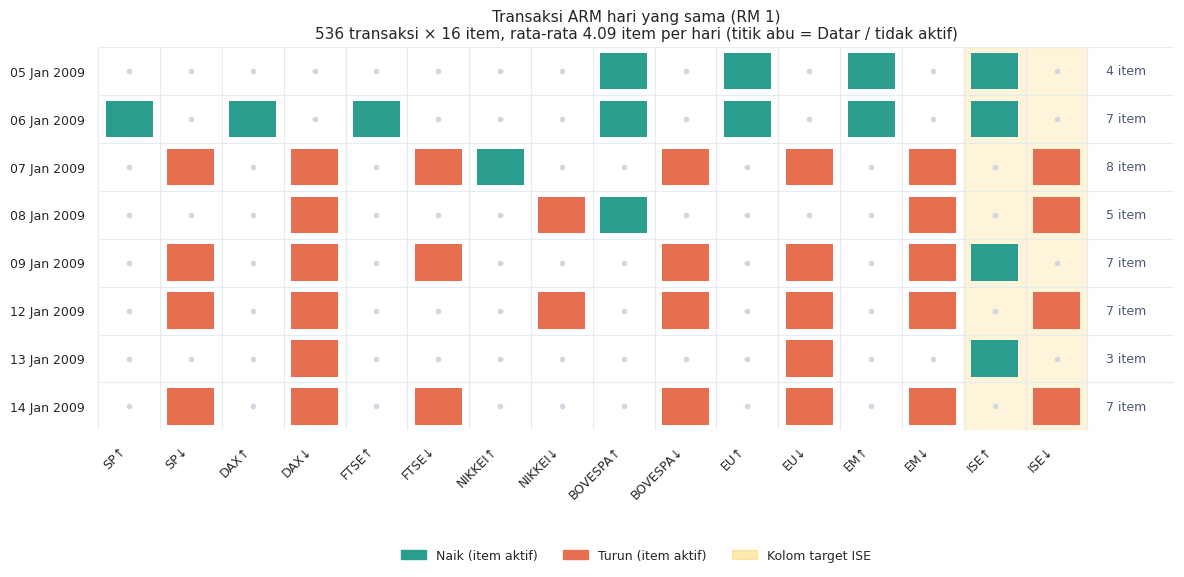

In [13]:
# Visualisasi tabel transaksi one-hot (cuplikan beberapa hari pertama)
def plot_onehot(X, n_hari=8, judul='Tabel transaksi one-hot'):
    sub = X.head(n_hari)
    labels = [item_label(c) for c in sub.columns]
    fig, ax = plt.subplots(figsize=(max(10, len(labels) * 0.75), 0.55 * n_hari + 1.8))

    for i, (tgl, row) in enumerate(sub.iterrows()):
        for j, (col, aktif) in enumerate(row.items()):
            if aktif:
                warna = COLOR['Up'] if col.endswith('_Up') else COLOR['Down']
                ax.add_patch(plt.Rectangle((j + .12, i + .12), .76, .76, color=warna, ec='none'))
            else:
                ax.plot(j + .5, i + .5, 'o', color='#d0d7e2', ms=3)
        ax.text(len(labels) + .3, i + .5, f'{int(row.sum())} item', va='center', fontsize=9, color='#4a5878')

    # sorot kolom target ISE
    ise_idx = [j for j, c in enumerate(sub.columns) if c.startswith('ISE')]
    if ise_idx:
        ax.axvspan(min(ise_idx), max(ise_idx) + 1, color='#fdbb05', alpha=.15, zorder=0)

    ax.set_xlim(0, len(labels) + 1.4); ax.set_ylim(n_hari, 0)
    ax.set_xticks(np.arange(len(labels)) + .5); ax.set_xticklabels(labels, rotation=45, ha='right', fontsize=9)
    ax.set_yticks(np.arange(n_hari) + .5); ax.set_yticklabels(sub.index.strftime('%d %b %Y'), fontsize=9)
    ax.set_xticks(np.arange(len(labels) + 1), minor=True); ax.set_yticks(np.arange(n_hari + 1), minor=True)
    ax.grid(which='minor', color='#e6ebf2', lw=.8); ax.grid(which='major', visible=False)
    ax.tick_params(which='minor', length=0)
    for s in ax.spines.values(): s.set_visible(False)

    handles = [plt.Rectangle((0, 0), 1, 1, color=COLOR['Up']), plt.Rectangle((0, 0), 1, 1, color=COLOR['Down']),
               plt.Rectangle((0, 0), 1, 1, color='#fdbb05', alpha=.3)]
    ax.legend(handles, ['Naik (item aktif)', 'Turun (item aktif)', 'Kolom target ISE'],
              ncol=3, loc='upper center', bbox_to_anchor=(.5, -.28), frameon=False, fontsize=9)
    ax.set_title(f'{judul}\n{X.shape[0]} transaksi × {X.shape[1]} item, '
                 f'rata-rata {X.sum(axis=1).mean():.2f} item per hari (titik abu = Datar / tidak aktif)', fontsize=11)
    plt.tight_layout(); plt.show()

plot_onehot(X_same, n_hari=8, judul='Transaksi ARM hari yang sama (RM 1)')

### 6.2 Mining aturan dan evaluasi

In [14]:
rules_same = mine_rules(X_same, TARGETS, ARM_SAME_MINSUP, ARM_SAME_MAXLEN)
sig_same = rules_same[rules_same['signifikan']]

summary = rules_same.groupby('target').agg(total_aturan=('rule', 'size'),
                                           signifikan=('signifikan', 'sum'),
                                           base_rate=('base_rate', 'first'))
display(summary)

for t in ['ISE↑', 'ISE↓']:
    print(f'\n10 aturan signifikan dengan lift tertinggi untuk {t}')
    display(sig_same[sig_same['target'] == t].nlargest(10, 'lift')[SHOW].round(4))

,total_aturan,signifikan,base_rate
target,,,
ISE↑,49,26,0.320896
ISE↓,45,27,0.218284



10 aturan signifikan dengan lift tertinggi untuk ISE↑


,rule,target,n_hari,support,confidence,base_rate,lift,improvement,q_value
0,EM↑ + EU↑ + SP↑,ISE↑,51,0.0951,0.8095,0.3209,2.5227,0.0568,0.0
1,BOVESPA↑ + DAX↑ + EM↑,ISE↑,48,0.0896,0.8000,0.3209,2.4930,0.0436,0.0
2,DAX↑ + EM↑ + SP↑,ISE↑,48,0.0896,0.7869,0.3209,2.4522,0.0396,0.0
3,BOVESPA↑ + EM↑ + EU↑,ISE↑,49,0.0914,0.7778,0.3209,2.4238,0.0251,0.0
4,EM↑ + FTSE↑ + SP↑,ISE↑,46,0.0858,0.7667,0.3209,2.3891,0.0615,0.0
5,BOVESPA↑ + EM↑ + FTSE↑,ISE↑,45,0.0840,0.7627,0.3209,2.3768,0.0704,0.0
9,BOVESPA↑ + DAX↑,ISE↑,59,0.1101,0.7564,0.3209,2.3572,0.1078,0.0
11,EM↑ + EU↑,ISE↑,70,0.1306,0.7527,0.3209,2.3456,0.1033,0.0
12,DAX↑ + EM↑,ISE↑,68,0.1269,0.7473,0.3209,2.3286,0.0986,0.0
17,BOVESPA↑ + EU↑,ISE↑,60,0.1119,0.7229,0.3209,2.2527,0.0735,0.0



10 aturan signifikan dengan lift tertinggi untuk ISE↓


,rule,target,n_hari,support,confidence,base_rate,lift,improvement,q_value
49,BOVESPA↓ + DAX↓ + EM↓,ISE↓,34,0.0634,0.7391,0.2183,3.3861,0.0631,0.0
50,BOVESPA↓ + EM↓ + EU↓,ISE↓,34,0.0634,0.7083,0.2183,3.2450,0.0417,0.0
55,DAX↓ + EM↓,ISE↓,48,0.0896,0.6761,0.2183,3.0971,0.1554,0.0
56,BOVESPA↓ + DAX↓,ISE↓,43,0.0802,0.6719,0.2183,3.0780,0.1512,0.0
57,BOVESPA↓ + EU↓,ISE↓,42,0.0784,0.6667,0.2183,3.0541,0.1467,0.0
61,BOVESPA↓ + EM↓ + FTSE↓,ISE↓,31,0.0578,0.6596,0.2183,3.0216,0.0305,0.0
62,BOVESPA↓ + FTSE↓ + SP↓,ISE↓,34,0.0634,0.6538,0.2183,2.9954,0.0248,0.0
63,EM↓ + EU↓ + SP↓,ISE↓,32,0.0597,0.6531,0.2183,2.9918,0.0215,0.0
65,EM↓ + EU↓,ISE↓,48,0.0896,0.6316,0.2183,2.8934,0.1116,0.0
67,BOVESPA↓ + FTSE↓,ISE↓,39,0.0728,0.6290,0.2183,2.8817,0.1330,0.0


### 6.3 Profil hubungan tiap indeks dengan ISE (aturan 1 antecedent)
Aturan dengan satu antecedent paling mudah dibandingkan antarindeks. Heatmap menampilkan lift; sel kosong berarti kombinasi tersebut tidak mencapai minimum support (terlalu jarang terjadi).

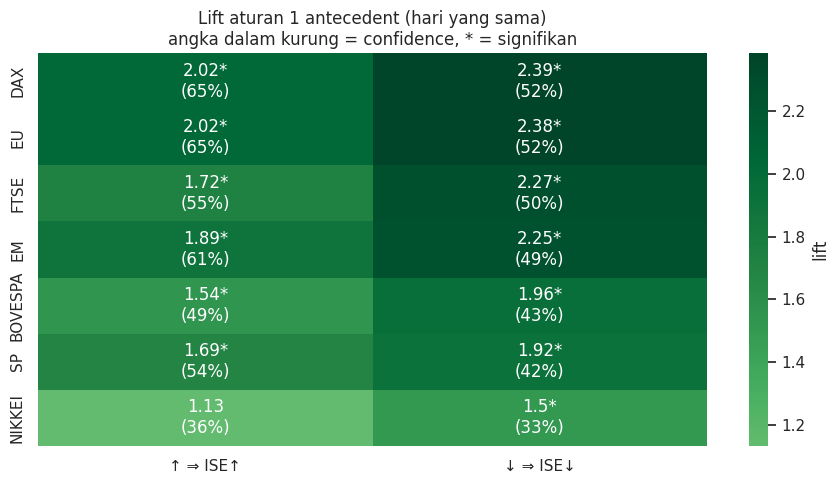

In [15]:
def single_profile(rules):
    one = rules[rules['n_items'] == 1].copy()
    one['indeks'] = one['rule'].str[:-1]
    one['arah'] = one['rule'].str[-1] + ' ⇒ ' + one['target']
    lift = one.pivot(index='indeks', columns='arah', values='lift')
    conf = one.pivot(index='indeks', columns='arah', values='confidence')
    sig = one.pivot(index='indeks', columns='arah', values='signifikan')
    cols = [c for c in ['↑ ⇒ ISE↑', '↓ ⇒ ISE↓', '↑ ⇒ ISE↓', '↓ ⇒ ISE↑'] if c in lift.columns]
    return lift[cols], conf[cols], sig[cols]

lift1, conf1, sig1 = single_profile(rules_same)
order = lift1.max(axis=1).sort_values(ascending=False).index
annot = lift1.loc[order].round(2).astype(str) + np.where(sig1.loc[order].fillna(False).astype(bool), '*', '') \
        + '\n(' + (conf1.loc[order] * 100).round(0).astype('Int64').astype(str) + '%)'
fig, ax = plt.subplots(figsize=(9, 5))
sns.heatmap(lift1.loc[order], annot=annot.where(lift1.loc[order].notna(), ''), fmt='', cmap='YlGn',
            center=1, ax=ax, cbar_kws={'label': 'lift'})
ax.set_title('Lift aturan 1 antecedent (hari yang sama)\nangka dalam kurung = confidence, * = signifikan')
ax.set_xlabel(''); ax.set_ylabel(''); plt.tight_layout(); plt.show()

### 6.4 Visualisasi seluruh aturan dan kontribusi indeks

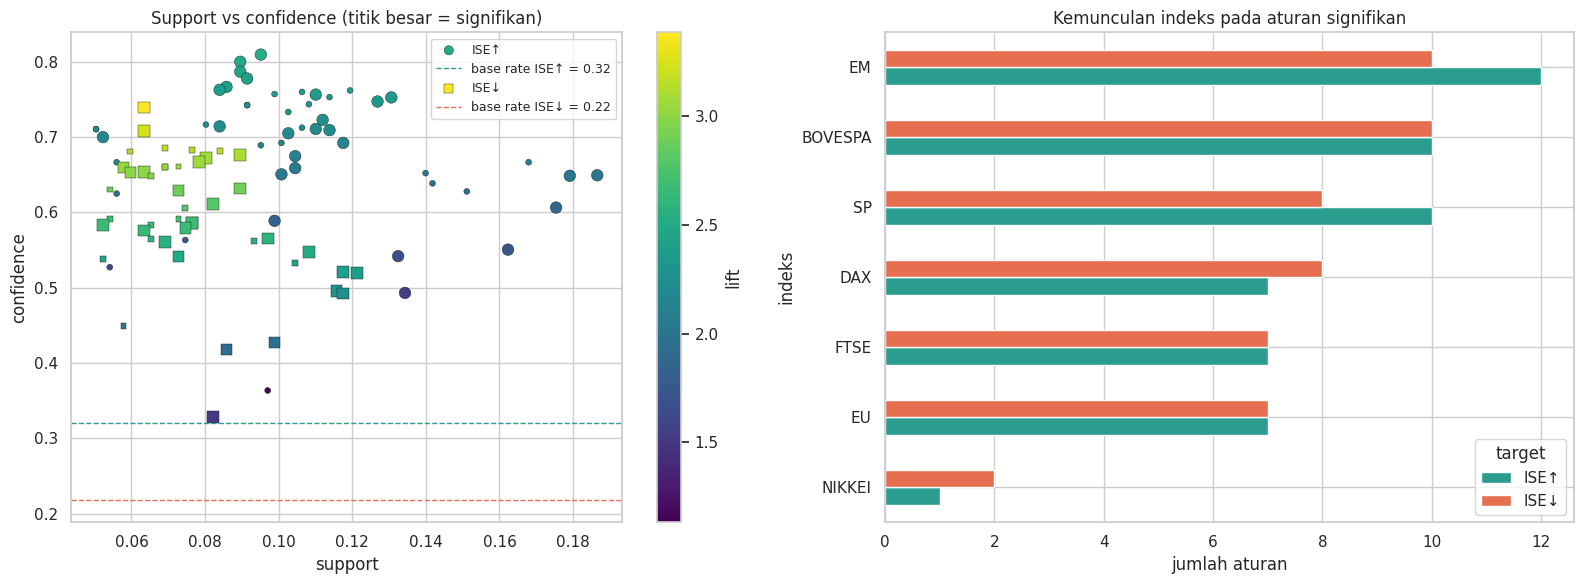

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for t, mk in [('ISE↑', 'o'), ('ISE↓', 's')]:
    d = rules_same[rules_same['target'] == t]
    sc = axes[0].scatter(d['support'], d['confidence'], c=d['lift'], cmap='viridis', marker=mk,
                         s=np.where(d['signifikan'], 70, 18), edgecolor='k', linewidth=.3, label=t,
                         vmin=rules_same['lift'].min(), vmax=rules_same['lift'].max())
    axes[0].axhline(d['base_rate'].iloc[0], ls='--', lw=1, color=COLOR['Up' if t == 'ISE↑' else 'Down'],
                    label=f'base rate {t} = {d["base_rate"].iloc[0]:.2f}')
fig.colorbar(sc, ax=axes[0], label='lift')
axes[0].set_xlabel('support'); axes[0].set_ylabel('confidence')
axes[0].set_title('Support vs confidence (titik besar = signifikan)'); axes[0].legend(fontsize=9)

# frekuensi tiap indeks pada aturan signifikan
freq = []
for _, r in sig_same.iterrows():
    for i in r['antecedents']:
        freq.append({'indeks': i.rsplit('_', 1)[0], 'target': r['target']})
freq = pd.DataFrame(freq).value_counts().unstack(fill_value=0)
freq = freq.loc[freq.sum(axis=1).sort_values().index, ['ISE↑', 'ISE↓']]
freq.plot(kind='barh', ax=axes[1], color=[COLOR['Up'], COLOR['Down']])
axes[1].set_title('Kemunculan indeks pada aturan signifikan'); axes[1].set_xlabel('jumlah aturan')
plt.tight_layout(); plt.show()

### 6.5 Stabilitas aturan antarperiode
Aturan *co-movement* yang benar seharusnya tetap berlaku pada periode lain. Mining diulang hanya pada 70% data awal (σ juga dihitung dari periode tersebut), lalu confidence dan lift setiap aturan signifikan dihitung ulang pada 30% data akhir.

In [17]:
val_same, cut, Xtr_s, Xte_s = temporal_validation(build_same, TARGETS, ARM_SAME_MINSUP, ARM_SAME_MAXLEN)
print(f'Periode latih: s/d {cut.date()} ({len(Xtr_s)} hari) | periode uji: {len(Xte_s)} hari')
print('Aturan signifikan di periode latih:', len(val_same))
print('Proporsi aturan dengan lift_uji > 1   :', f"{(val_same['lift_uji'] > 1).mean():.1%}")
print('Median confidence latih vs uji        :', f"{val_same['confidence'].median():.3f} vs {val_same['conf_uji'].median():.3f}")
display(val_same.groupby('target')[['confidence', 'conf_uji', 'base_rate', 'base_uji', 'lift', 'lift_uji']].median().round(3))

Periode latih: s/d 2010-06-30 (375 hari) | periode uji: 161 hari
Aturan signifikan di periode latih: 52
Proporsi aturan dengan lift_uji > 1   : 100.0%
Median confidence latih vs uji        : 0.665 vs 0.600


,confidence,conf_uji,base_rate,base_uji,lift,lift_uji
target,,,,,,
ISE↑,0.727,0.667,0.317,0.236,2.292,2.825
ISE↓,0.625,0.556,0.216,0.193,2.894,2.885



### 6.6 Interpretasi ARM hari yang sama
**Gambaran umum.** Dari 94 aturan yang mengarah ke ISE, 53 lolos uji signifikansi dan improvement (26 untuk ISE↑, 27 untuk ISE↓). Base rate: ISE naik pada 32,1% hari dan turun pada 21,8% hari.

**Indeks tunggal.** Eropa memberi sinyal paling kuat. DAX↑ atau EU↑ menaikkan peluang ISE↑ menjadi 65% (lift 2,02), dan DAX↓ menaikkan peluang ISE↓ menjadi 52% (lift 2,39). NIKKEI paling lemah: NIKKEI↑ ⇒ ISE↑ tidak signifikan (lift 1,13), dan NIKKEI↓ ⇒ ISE↓ hanya lift 1,50.

**Kombinasi terkuat.** Aturan dengan lift tertinggi didominasi kombinasi **satu indeks Eropa, satu indeks Amerika, dan EM yang bergerak searah**:
* `EM↑ + EU↑ + SP↑ ⇒ ISE↑`: terjadi 51 hari, ISE ikut naik pada 81% kejadian (lift 2,52).
* `BOVESPA↓ + DAX↓ + EM↓ ⇒ ISE↓`: terjadi 34 hari, ISE ikut turun pada 74% kejadian (lift 3,39).
* Versi dua item yang lebih sering terjadi tetap kuat: `EM↑ + EU↑` (70 hari, 75%) dan `DAX↓ + EM↓` (48 hari, 68%).

Artinya ISE paling mungkin naik atau turun ketika pergerakan bersifat **global dan serentak**, bukan ketika hanya satu wilayah yang bergerak. Menambah indeks Eropa kedua umumnya hampir tidak menaikkan confidence (improvement di bawah 0,02 sehingga tersaring), sesuai temuan korelasi tinggi antarindeks Eropa.

**Asimetri.** Lift aturan ISE↓ (sekitar 3) lebih tinggi dari ISE↑ (sekitar 2,5). Ketika pasar global turun bersamaan, peluang ISE turun naik kira-kira tiga kali lipat dari kondisi normal. Sentimen negatif global lebih kuat terbawa ke ISE dibanding sentimen positif.

**Stabilitas.** Ke-52 aturan signifikan dari periode latih (s/d Juni 2010) seluruhnya tetap memiliki lift > 1 pada periode uji, dengan median confidence 0,665 di periode latih dan 0,600 di periode uji. *Co-movement* ini bersifat struktural, bukan kebetulan satu periode.

**Batasan tafsir.** SP, BOVESPA, dan EM tutup setelah Istanbul, sehingga aturan ini menggambarkan kebersamaan pergerakan, bukan pasar mana yang memengaruhi pasar mana.


## 7. ARM dengan Lag t-1 (Rumusan Masalah 2)
### 7.1 Pembentukan transaksi lag
Antecedent berisi arah ketujuh indeks global dan arah ISE sendiri pada hari t-1 (diberi akhiran `(t-1)`), sedangkan konsekuen adalah arah ISE hari t. Baris pertama dibuang karena tidak memiliki hari sebelumnya. Minimum support diturunkan menjadi 3% (sekitar 16 hari) karena asosiasi lintas hari secara alami lebih lemah, dan antecedent dibatasi maksimal dua item agar setiap aturan masih didukung jumlah hari yang memadai.

In [18]:
def build_lag(st):
    prev = onehot(st.shift(1), GLOBAL + ['ISE'], suffix='(t-1)')
    now = onehot(st, ['ISE'])
    return prev.join(now).iloc[1:]

X_lag = build_lag(states)
print('Transaksi:', X_lag.shape[0], '| item:', X_lag.shape[1])
X_lag.head(3)

Transaksi: 535 | item: 18


,SP(t-1)_Up,SP(t-1)_Down,DAX(t-1)_Up,DAX(t-1)_Down,FTSE(t-1)_Up,FTSE(t-1)_Down,NIKKEI(t-1)_Up,NIKKEI(t-1)_Down,BOVESPA(t-1)_Up,BOVESPA(t-1)_Down,EU(t-1)_Up,EU(t-1)_Down,EM(t-1)_Up,EM(t-1)_Down,ISE(t-1)_Up,ISE(t-1)_Down,ISE_Up,ISE_Down
date,,,,,,,,,,,,,,,,,,
2009-01-06,False,False,False,False,False,False,False,False,True,False,True,False,True,False,True,False,True,False
2009-01-07,True,False,True,False,True,False,False,False,True,False,True,False,True,False,True,False,False,True
2009-01-08,False,True,False,True,False,True,True,False,False,True,False,True,False,True,False,True,False,True


### 7.2 Mining aturan dan evaluasi

In [19]:
rules_lag = mine_rules(X_lag, TARGETS, ARM_LAG_MINSUP, ARM_LAG_MAXLEN)
sig_lag = rules_lag[rules_lag['signifikan']]
display(rules_lag.groupby('target').agg(total_aturan=('rule', 'size'), signifikan=('signifikan', 'sum'),
                                        base_rate=('base_rate', 'first')))
print('Seluruh aturan lag yang signifikan:')
display(sig_lag.sort_values('lift', ascending=False)[SHOW].round(4))
print('Aturan dengan p-value < 0,05 sebelum koreksi tetapi gugur setelah koreksi BH / improvement:')
display(rules_lag[(rules_lag['p_value'] < 0.05) & ~rules_lag['signifikan']].nsmallest(8, 'p_value')[SHOW].round(4))

,total_aturan,signifikan,base_rate
target,,,
ISE↑,59,2,0.319626
ISE↓,43,4,0.218692


Seluruh aturan lag yang signifikan:


,rule,target,n_hari,support,confidence,base_rate,lift,improvement,q_value
0,BOVESPA(t-1)↑ + NIKKEI(t-1)↓,ISE↑,17,0.0318,0.5862,0.3196,1.8340,0.1426,0.0361
59,FTSE(t-1)↓ + SP(t-1)↓,ISE↓,25,0.0467,0.3788,0.2187,1.7321,0.0424,0.0233
61,EU(t-1)↓ + SP(t-1)↓,ISE↓,26,0.0486,0.3768,0.2187,1.7230,0.0404,0.0233
62,BOVESPA(t-1)↓,ISE↓,43,0.0804,0.3496,0.2187,1.5986,0.1309,0.0091
66,SP(t-1)↓,ISE↓,37,0.0692,0.3364,0.2187,1.5381,0.1177,0.0233
7,NIKKEI(t-1)↓,ISE↑,59,0.1103,0.4436,0.3196,1.3879,0.1240,0.0186


Aturan dengan p-value < 0,05 sebelum koreksi tetapi gugur setelah koreksi BH / improvement:


,rule,target,n_hari,support,confidence,base_rate,lift,improvement,q_value
60,BOVESPA(t-1)↓ + ISE(t-1)↓,ISE↓,20,0.0374,0.3774,0.2187,1.7255,0.0278,0.0603
64,DAX(t-1)↓ + SP(t-1)↓,ISE↓,24,0.0449,0.3429,0.2187,1.5678,0.0065,0.0852
63,BOVESPA(t-1)↓ + EU(t-1)↓,ISE↓,22,0.0411,0.3492,0.2187,1.5968,-0.0004,0.0852
4,EM(t-1)↓ + NIKKEI(t-1)↓,ISE↑,31,0.0579,0.4559,0.3196,1.4263,0.0123,0.0852
67,BOVESPA(t-1)↓ + EM(t-1)↓,ISE↓,23,0.0430,0.3333,0.2187,1.5242,-0.0163,0.1168
65,BOVESPA(t-1)↓ + FTSE(t-1)↓,ISE↓,21,0.0393,0.3387,0.2187,1.5488,-0.0109,0.1206
1,ISE(t-1)↓ + NIKKEI(t-1)↓,ISE↑,21,0.0393,0.4773,0.3196,1.4932,0.0337,0.1315
2,FTSE(t-1)↓ + NIKKEI(t-1)↓,ISE↑,22,0.0411,0.4681,0.3196,1.4645,0.0245,0.1318


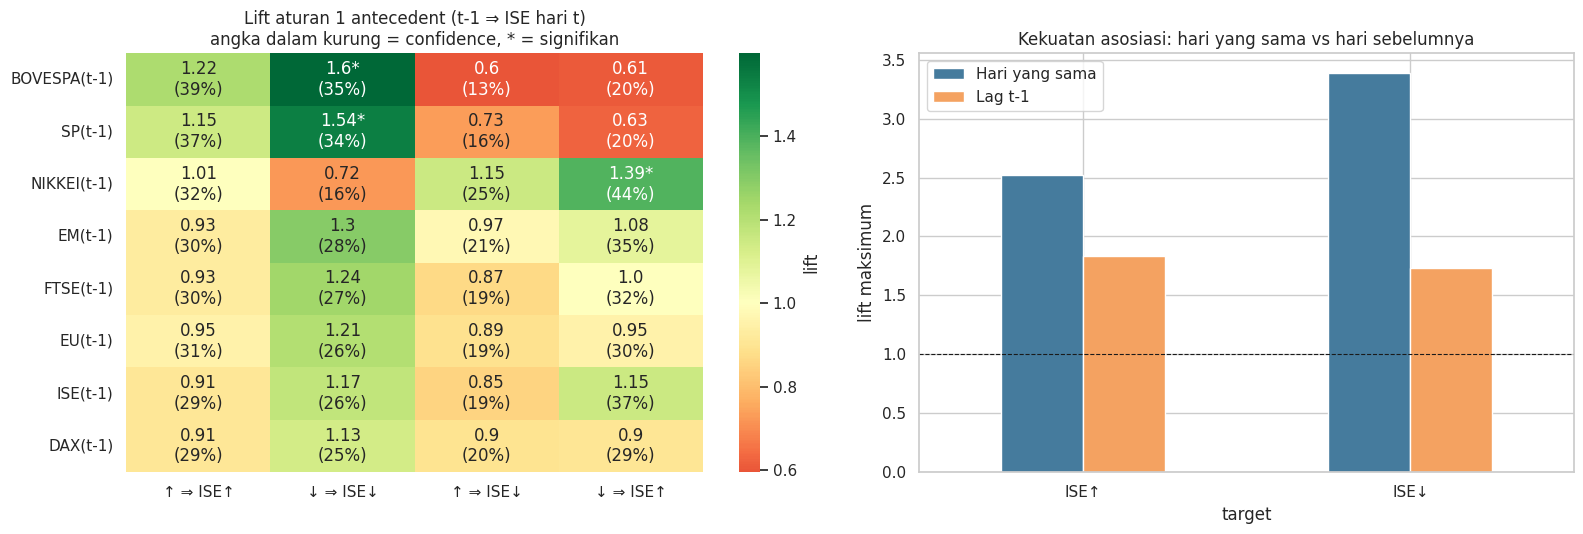

In [20]:
lift1L, conf1L, sig1L = single_profile(rules_lag)
orderL = lift1L.max(axis=1).sort_values(ascending=False).index
annotL = lift1L.loc[orderL].round(2).astype(str) + np.where(sig1L.loc[orderL].fillna(False).astype(bool), '*', '') \
         + '\n(' + (conf1L.loc[orderL] * 100).round(0).astype('Int64').astype(str) + '%)'
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5), gridspec_kw={'width_ratios': [1.1, 1]})
sns.heatmap(lift1L.loc[orderL], annot=annotL.where(lift1L.loc[orderL].notna(), ''), fmt='', cmap='RdYlGn',
            center=1, ax=axes[0], cbar_kws={'label': 'lift'})
axes[0].set_title('Lift aturan 1 antecedent (t-1 ⇒ ISE hari t)\nangka dalam kurung = confidence, * = signifikan')
axes[0].set_xlabel(''); axes[0].set_ylabel('')

# perbandingan kekuatan: lift terbaik ARM hari yang sama vs ARM lag
cmp = pd.DataFrame({'Hari yang sama': rules_same.groupby('target')['lift'].max(),
                    'Lag t-1': rules_lag.groupby('target')['lift'].max()})
cmp.plot(kind='bar', ax=axes[1], color=['#457b9d', '#f4a261'], rot=0)
axes[1].axhline(1, color='k', lw=.8, ls='--'); axes[1].set_ylabel('lift maksimum')
axes[1].set_title('Kekuatan asosiasi: hari yang sama vs hari sebelumnya')
plt.tight_layout(); plt.show()

### 7.3 Validasi temporal: apakah aturan lag benar-benar bisa menjadi petunjuk?
Rumusan masalah 2 bersifat prediktif, sehingga aturan yang hanya berlaku di dalam sampel belum cukup. Dua pemeriksaan dilakukan:

1. **Latih-uji:** mining hanya pada 70% data awal, aturan signifikan diuji pada 30% data akhir.
2. **Stabilitas subperiode:** aturan signifikan dari data penuh dihitung ulang terpisah pada kedua subperiode.

Periode latih s/d 2010-06-30 (374 hari), periode uji 161 hari
Aturan signifikan di periode latih: 3


,rule,target,confidence,base_rate,lift,n_muncul,conf_uji,base_uji,lift_uji
0,FTSE(t-1)↓ + SP(t-1)↓,ISE↓,0.389,0.217,1.796,9,0.111,0.193,0.577
1,EU(t-1)↓ + SP(t-1)↓,ISE↓,0.386,0.217,1.782,10,0.100,0.193,0.519
2,SP(t-1)↓,ISE↓,0.352,0.217,1.627,18,0.111,0.193,0.577



Stabilitas aturan signifikan (data penuh) pada subperiode P1 (2009 s/d pertengahan 2010) dan P2 (sisanya):


,rule,target,n_P1,conf_P1,lift_P1,n_P2,conf_P2,lift_P2
0,BOVESPA(t-1)↑ + NIKKEI(t-1)↓,ISE↑,25,0.600,1.740,4,0.500,1.917
1,NIKKEI(t-1)↓,ISE↑,99,0.465,1.347,34,0.382,1.466
2,FTSE(t-1)↓ + SP(t-1)↓,ISE↓,55,0.436,1.920,11,0.091,0.457
3,EU(t-1)↓ + SP(t-1)↓,ISE↓,59,0.424,1.864,10,0.100,0.503
4,BOVESPA(t-1)↓,ISE↓,87,0.356,1.568,36,0.333,1.677
5,SP(t-1)↓,ISE↓,90,0.378,1.662,20,0.150,0.755


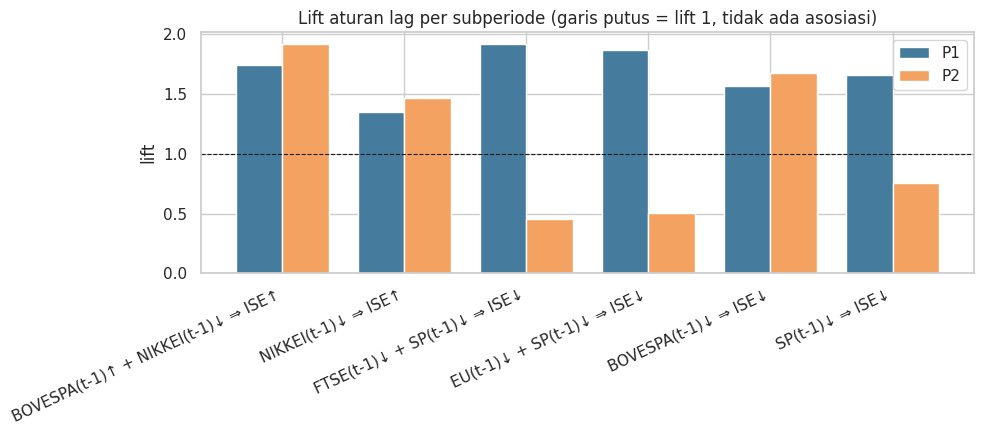

In [21]:
val_lag, cut, Xtr_l, Xte_l = temporal_validation(build_lag, TARGETS, ARM_LAG_MINSUP, ARM_LAG_MAXLEN)
print(f'Periode latih s/d {cut.date()} ({len(Xtr_l)} hari), periode uji {len(Xte_l)} hari')
print('Aturan signifikan di periode latih:', len(val_lag))
display(val_lag[['rule', 'target', 'confidence', 'base_rate', 'lift', 'n_muncul', 'conf_uji', 'base_uji', 'lift_uji']].round(3))

# stabilitas subperiode untuk aturan signifikan data penuh
p1 = evaluate_rules_on(sig_lag, X_lag[X_lag.index < cut])[['rule', 'target', 'n_muncul', 'conf_uji', 'lift_uji']]
p2 = evaluate_rules_on(sig_lag, X_lag[X_lag.index >= cut])[['n_muncul', 'conf_uji', 'lift_uji']]
stab = pd.concat([p1.rename(columns={'n_muncul': 'n_P1', 'conf_uji': 'conf_P1', 'lift_uji': 'lift_P1'}),
                  p2.rename(columns={'n_muncul': 'n_P2', 'conf_uji': 'conf_P2', 'lift_uji': 'lift_P2'})], axis=1)
print('\nStabilitas aturan signifikan (data penuh) pada subperiode P1 (2009 s/d pertengahan 2010) dan P2 (sisanya):')
display(stab.round(3))

fig, ax = plt.subplots(figsize=(10, 4.5))
x = np.arange(len(stab)); w = .38
ax.bar(x - w/2, stab['lift_P1'], w, label='P1', color='#457b9d')
ax.bar(x + w/2, stab['lift_P2'], w, label='P2', color='#f4a261')
ax.axhline(1, color='k', ls='--', lw=.8)
ax.set_xticks(x); ax.set_xticklabels(stab['rule'] + ' ⇒ ' + stab['target'], rotation=25, ha='right')
ax.set_ylabel('lift'); ax.set_title('Lift aturan lag per subperiode (garis putus = lift 1, tidak ada asosiasi)'); ax.legend()
plt.tight_layout(); plt.show()


### 7.4 Interpretasi ARM lag
**Sinyal ada, tetapi jauh lebih lemah.** Hanya 6 dari 102 aturan lag yang signifikan, dibanding 53 aturan pada hari yang sama. Lift maksimum turun dari 3,39 menjadi 1,83.

**Aturan yang signifikan:**
* `BOVESPA(t-1)↓ ⇒ ISE↓`: confidence 35,0% vs base rate 21,9% (lift 1,60; 43 hari).
* `SP(t-1)↓ ⇒ ISE↓`: 33,6% (lift 1,54). Kombinasi dengan Eropa (`FTSE(t-1)↓ + SP(t-1)↓`, `EU(t-1)↓ + SP(t-1)↓`) naik sedikit ke sekitar 38%.
* `NIKKEI(t-1)↓ ⇒ ISE↑`: 44,4% vs 32,0% (lift 1,39; 59 hari), arahnya berlawanan.
* `BOVESPA(t-1)↑ + NIKKEI(t-1)↓ ⇒ ISE↑`: 58,6%, tetapi hanya 17 hari.

Sinyal dari Amerika hanya muncul untuk arah **turun**. `BOVESPA(t-1)↑ ⇒ ISE↑` (lift 1,22) dan `SP(t-1)↑ ⇒ ISE↑` (lift 1,15) tidak signifikan. Kabar buruk dari Amerika semalam terbawa ke Istanbul, kabar baik tidak terlalu.

**Validasi temporal mengubah kesimpulan untuk sebagian aturan:**
* Ketika mining hanya memakai periode latih, aturan yang lolos hanya tiga aturan berbasis SP, dan ketiganya **gagal** di periode uji: confidence turun ke 10-11%, di bawah base rate 19% (lift 0,52-0,58), dengan hanya 9-18 kejadian.
* Uji subperiode menunjukkan pemisahan yang jelas. `BOVESPA(t-1)↓ ⇒ ISE↓` stabil (lift 1,57 di P1 dan 1,68 di P2), begitu pula `NIKKEI(t-1)↓ ⇒ ISE↑` (1,35 dan 1,47). Aturan yang memuat SP runtuh di P2 (lift 0,46-0,76).

**Jawaban sementara RM 2.** Kondisi global hari sebelumnya hanya memberi petunjuk lemah. Petunjuk yang paling dapat dipegang adalah **penurunan BOVESPA kemarin**, yang menaikkan peluang ISE turun dari sekitar 22% menjadi sekitar 35%. Namun pada 65% kejadian ISE tetap tidak turun, sehingga aturan ini lebih cocok dibaca sebagai penanda kenaikan risiko daripada alat prediksi arah. Aturan `NIKKEI(t-1)↓ ⇒ ISE↑` stabil antarperiode tetapi tidak kokoh terhadap perubahan ambang (Bagian 9), jadi perlu diperlakukan sebagai hipotesis.


## 8. Sequential Pattern Mining (Rumusan Masalah 3)
### 8.1 Konstruksi basis data sekuens
* **Elemen (itemset):** satu sesi perdagangan. Setiap hari dipecah menjadi tiga elemen berurutan S1 → S2 → S3 sesuai tabel pada Bagian 5.3, sehingga urutan waktu di dalam satu hari juga terekam. Indeks yang tutup pada sesi yang sama berada dalam satu itemset.
* **Item:** arah indeks pada sesi itu (`DAX_Down`, `NIKKEI_Up`, ...). Kondisi Flat tidak dijadikan item.
* **Sekuens:** jendela geser 3 hari bursa berturut-turut (9 elemen), bergeser satu hari. Support sebuah pola = proporsi jendela yang memuat pola tersebut.

Analisis dilakukan pada dua tingkat:
1. **Antarpasar (indeks):** 8 indeks individual.
2. **Antarwilayah:** indeks digabung per wilayah. Return tiap indeks dibagi σ-nya, dirata-ratakan dalam wilayah, lalu didiskretisasi dengan aturan K·σ yang sama: ASIA = NIKKEI, TURKI = ISE, EROPA = DAX + FTSE + EU, AMERIKA = SP + BOVESPA, EM = MSCI EM.

In [22]:
SESS_IDX = [['NIKKEI'], ['ISE', 'DAX', 'FTSE', 'EU'], ['SP', 'BOVESPA', 'EM']]
SESS_REG = [['ASIA'], ['TURKI', 'EROPA'], ['AMERIKA', 'EM']]

def build_windows(st, sessions, W=SPM_WINDOW):
    elems = []
    for _, row in st.iterrows():
        for group in sessions:
            elems.append(frozenset(f'{c}_{row[c]}' for c in group if row[c] != 'Flat'))
    S = len(sessions)
    return [elems[i * S:(i + W) * S] for i in range(len(st) - W + 1)]

# wilayah: rata-rata return terstandar (dibagi sigma, tanpa centering agar nol tetap berarti 'tidak bergerak')
scaled = ret / ret.std()
regions = pd.DataFrame({'ASIA': scaled['NIKKEI'], 'TURKI': scaled['ISE'],
                        'EROPA': scaled[['DAX', 'FTSE', 'EU']].mean(axis=1),
                        'AMERIKA': scaled[['SP', 'BOVESPA']].mean(axis=1), 'EM': scaled['EM']})
reg_states = discretize(regions, regions.std())

db_idx = build_windows(states, SESS_IDX)
db_reg = build_windows(reg_states, SESS_REG)
print('Jumlah sekuens (jendela):', len(db_idx))
print('\nContoh satu sekuens tingkat wilayah (3 hari x 3 sesi):')
for d in range(SPM_WINDOW):
    print(f'  hari {d+1}:', ' → '.join('{' + ', '.join(sorted(e)) + '}' for e in db_reg[0][d*3:(d+1)*3]))

Jumlah sekuens (jendela): 534

Contoh satu sekuens tingkat wilayah (3 hari x 3 sesi):
  hari 1: {} → {TURKI_Up} → {AMERIKA_Up, EM_Up}
  hari 2: {} → {EROPA_Up, TURKI_Up} → {AMERIKA_Up, EM_Up}
  hari 3: {ASIA_Up} → {EROPA_Down, TURKI_Down} → {AMERIKA_Down, EM_Down}


### 8.2 Algoritma PrefixSpan
mlxtend tidak menyediakan SPM, dan paket `prefixspan` di PyPI hanya mendukung sekuens berisi item tunggal (tidak bisa merepresentasikan beberapa indeks yang tutup pada sesi yang sama). Karena itu PrefixSpan ditulis ulang di bawah dengan dukungan itemset:
* **S-extension:** menambahkan item sebagai elemen baru setelah elemen terakhir pola.
* **I-extension:** menambahkan item ke elemen terakhir pola (terjadi pada sesi yang sama).

Untuk setiap pola, algoritma menyimpan posisi-posisi elemen terakhir yang cocok di setiap sekuens (*projected database*), sehingga support dihitung tanpa memindai ulang seluruh data.

In [23]:
def prefixspan(db, min_count, max_items=SPM_MAX_ITEMS, max_elems=SPM_MAX_ELEMS):
    results = []

    def grow(pattern, endpos, n_items):
        if n_items >= max_items:
            return
        last = pattern[-1]
        i_cnt, s_cnt = {}, {}
        for sid, poss in endpos.items():
            seq, i_set, s_set = db[sid], set(), set()
            for p in poss:                                   # kandidat i-extension
                i_set.update(x for x in seq[p] if x > last[-1])
            for q in range(poss[0] + 1, len(seq)):          # kandidat s-extension
                s_set.update(seq[q])
            for x in i_set: i_cnt[x] = i_cnt.get(x, 0) + 1
            for x in s_set: s_cnt[x] = s_cnt.get(x, 0) + 1

        for x in sorted(k for k, c in i_cnt.items() if c >= min_count):
            new_end = {sid: [p for p in poss if x in db[sid][p]] for sid, poss in endpos.items()}
            new_end = {k: v for k, v in new_end.items() if v}
            new_pat = pattern[:-1] + [last + (x,)]
            results.append((new_pat, len(new_end)))
            grow(new_pat, new_end, n_items + 1)

        if len(pattern) < max_elems:
            for x in sorted(k for k, c in s_cnt.items() if c >= min_count):
                new_end = {}
                for sid, poss in endpos.items():
                    qs = [q for q in range(poss[0] + 1, len(db[sid])) if x in db[sid][q]]
                    if qs: new_end[sid] = qs
                new_pat = pattern + [(x,)]
                results.append((new_pat, len(new_end)))
                grow(new_pat, new_end, n_items + 1)

    first = {}
    for sid, seq in enumerate(db):
        for p, el in enumerate(seq):
            for x in el:
                first.setdefault(x, {}).setdefault(sid, []).append(p)
    for x in sorted(first):
        if len(first[x]) >= min_count:
            results.append(([(x,)], len(first[x])))
            grow([(x,)], first[x], 1)
    return results

def pattern_label(p):
    return ' → '.join('{' + ', '.join(item_label(i) for i in el) + '}' for el in p)

### 8.3 Evaluasi pola dengan dua model nol (permutation test)
Support saja menyesatkan pada data ini: dalam jendela 3 hari, pola seperti `{SP↑} → {NIKKEI↑}` bisa sering muncul hanya karena masing-masing kejadian memang umum. Setiap pola dengan minimal dua elemen karena itu dibandingkan dengan support yang diharapkan di bawah dua skenario acak (masing-masing 200 permutasi):

| Model nol | Cara mengacak | Yang dihancurkan | Pola yang lolos berarti |
|---|---|---|---|
| **Independen** | kolom tiap pasar diacak terpisah | semua keterkaitan antarpasar | ada keterkaitan antarpasar (termasuk *co-movement* dalam satu hari) |
| **Temporal** | urutan hari diacak, isi tiap hari utuh | hanya urutan antarhari | ada struktur **lintas hari** yang tidak bisa dijelaskan oleh *co-movement* harian |

`lift = support aktual / rata-rata support acak`, p-value empiris = (1 + jumlah permutasi dengan support ≥ aktual) / (1 + 200), lalu dikoreksi BH. Pola dikategorikan:
* **Transmisi lintas hari:** signifikan terhadap model nol temporal.
* **Co-movement / urutan dalam hari:** signifikan terhadap model nol independen saja.
* **Tidak bermakna:** sisanya, sering muncul karena kebetulan.

Penghitungan support pada data permutasi memakai representasi bitmask dan operasi vektor NumPy agar cepat.

In [24]:
def encode(db, vocab):
    E = np.zeros((len(db), len(db[0])), dtype=np.int64)
    for i, seq in enumerate(db):
        for p, el in enumerate(seq):
            for x in el:
                E[i, p] |= 1 << vocab[x]
    return E

def support_vec(E, pattern, vocab):
    # pencocokan greedy paling awal, divektorisasi untuk semua sekuens sekaligus
    n, L = E.shape
    pos, ok, cols = np.full(n, -1), np.ones(n, bool), np.arange(L)
    for el in pattern:
        m = sum(1 << vocab[x] for x in el)
        match = ((E & m) == m) & (cols[None, :] > pos[:, None])
        found = match.any(axis=1)
        ok &= found
        pos = np.where(found, match.argmax(axis=1), L)
    return ok.mean()

def run_spm(st, sessions, label):
    db = build_windows(st, sessions)
    vocab = {f'{c}_{s}': i for i, (c, s) in enumerate((c, s) for g in sessions for c in g for s in ['Up', 'Down'])}
    pats = prefixspan(db, int(np.ceil(SPM_MINSUP * len(db))))
    multi = [p for p, _ in pats if len(p) >= 2]
    print(f'[{label}] pola frekuen: {len(pats)} | pola >= 2 elemen yang diuji: {len(multi)}')

    E = encode(db, vocab)
    obs = np.array([support_vec(E, p, vocab) for p in multi])
    null_ind, null_tmp = np.zeros((N_PERM, len(multi))), np.zeros((N_PERM, len(multi)))
    for b in range(N_PERM):
        shuf_ind = st.apply(lambda s: rng.permutation(s.values))           # acak per pasar
        shuf_tmp = st.iloc[rng.permutation(len(st))]                        # acak urutan hari
        Ei, Et = encode(build_windows(shuf_ind, sessions), vocab), encode(build_windows(shuf_tmp, sessions), vocab)
        null_ind[b] = [support_vec(Ei, p, vocab) for p in multi]
        null_tmp[b] = [support_vec(Et, p, vocab) for p in multi]

    res = pd.DataFrame({'pola': [pattern_label(p) for p in multi], 'raw': multi,
                        'n_elemen': [len(p) for p in multi], 'support': obs,
                        'lift_ind': obs / null_ind.mean(0), 'p_ind': (1 + (null_ind >= obs).sum(0)) / (N_PERM + 1),
                        'lift_tmp': obs / null_tmp.mean(0), 'p_tmp': (1 + (null_tmp >= obs).sum(0)) / (N_PERM + 1)})
    res['q_ind'], res['q_tmp'] = bh_adjust(res['p_ind']), bh_adjust(res['p_tmp'])
    res['kategori'] = np.select(
        [(res['q_tmp'] < ALPHA) & (res['lift_tmp'] > 1), (res['q_ind'] < ALPHA) & (res['lift_ind'] > 1)],
        ['Transmisi lintas hari', 'Co-movement / urutan dalam hari'], 'Tidak bermakna')
    return res

SPM_SHOW = ['pola', 'support', 'lift_ind', 'q_ind', 'lift_tmp', 'q_tmp', 'kategori']

### 8.4 Pola sekuensial antarpasar (tingkat indeks)

In [25]:
spm_idx = run_spm(states, SESS_IDX, 'indeks')
display(spm_idx['kategori'].value_counts().to_frame('jumlah pola'))

print('Transmisi lintas hari: 12 pola dengan lift temporal tertinggi')
display(spm_idx[spm_idx['kategori'] == 'Transmisi lintas hari'].nlargest(12, 'lift_tmp')[SPM_SHOW].round(3))
print('Co-movement / urutan dalam hari: 8 pola dengan lift independen tertinggi')
display(spm_idx[spm_idx['kategori'] == 'Co-movement / urutan dalam hari'].nlargest(8, 'lift_ind')[SPM_SHOW].round(3))
print('Pola yang melibatkan ISE dan bermakna secara temporal:')
display(spm_idx[spm_idx['pola'].str.contains('ISE') & (spm_idx['kategori'] == 'Transmisi lintas hari')]
        .sort_values('lift_tmp', ascending=False)[SPM_SHOW].round(3))

[indeks] pola frekuen: 316 | pola >= 2 elemen yang diuji: 270


,jumlah pola
kategori,
Co-movement / urutan dalam hari,201
Tidak bermakna,36
Transmisi lintas hari,33


Transmisi lintas hari: 12 pola dengan lift temporal tertinggi


,pola,support,lift_ind,q_ind,lift_tmp,q_tmp,kategori
58,"{DAX↑, EU↑} → {SP↑} → {NIKKEI↑}",0.206,11.696,0.006,1.962,0.041,Transmisi lintas hari
84,{DAX↑} → {SP↑} → {NIKKEI↑},0.210,3.609,0.006,1.929,0.041,Transmisi lintas hari
10,"{DAX↓, EU↓, FTSE↓} → {NIKKEI↓}",0.206,25.581,0.006,1.927,0.041,Transmisi lintas hari
30,"{DAX↓, FTSE↓} → {NIKKEI↓}",0.212,6.022,0.006,1.917,0.041,Transmisi lintas hari
137,{EU↑} → {SP↑} → {NIKKEI↑},0.210,3.449,0.006,1.867,0.041,Transmisi lintas hari
97,"{EU↓, FTSE↓} → {NIKKEI↓}",0.234,6.337,0.006,1.859,0.041,Transmisi lintas hari
266,{SP↓} → {NIKKEI↓},0.243,1.864,0.006,1.858,0.041,Transmisi lintas hari
20,"{DAX↓, EU↓} → {NIKKEI↓}",0.228,6.369,0.006,1.823,0.041,Transmisi lintas hari
168,{FTSE↑} → {SP↑} → {NIKKEI↑},0.204,3.318,0.006,1.818,0.041,Transmisi lintas hari
1,"{BOVESPA↑, SP↑} → {NIKKEI↑}",0.208,4.337,0.006,1.792,0.041,Transmisi lintas hari


Co-movement / urutan dalam hari: 8 pola dengan lift independen tertinggi


,pola,support,lift_ind,q_ind,lift_tmp,q_tmp,kategori
11,"{DAX↓, EU↓, FTSE↓} → {SP↓}",0.316,25.762,0.006,1.022,0.503,Co-movement / urutan dalam hari
9,"{DAX↓, EU↓, FTSE↓} → {EM↓}",0.322,23.243,0.006,1.054,0.306,Co-movement / urutan dalam hari
8,"{DAX↓, EU↓, FTSE↓} → {BOVESPA↓}",0.296,20.983,0.006,1.020,0.503,Co-movement / urutan dalam hari
17,"{DAX↓, EU↓} → {BOVESPA↓, SP↓}",0.279,20.723,0.006,1.006,0.646,Co-movement / urutan dalam hari
27,"{DAX↓, FTSE↓} → {BOVESPA↓, SP↓}",0.264,18.762,0.006,1.019,0.542,Co-movement / urutan dalam hari
13,"{DAX↓, EU↓, ISE↓} → {EM↓}",0.247,18.082,0.006,1.024,0.480,Co-movement / urutan dalam hari
94,"{EU↓, FTSE↓} → {BOVESPA↓, SP↓}",0.262,17.489,0.006,1.002,0.687,Co-movement / urutan dalam hari
14,"{DAX↓, EU↓, ISE↓} → {SP↓}",0.223,17.049,0.006,1.033,0.381,Co-movement / urutan dalam hari


Pola yang melibatkan ISE dan bermakna secara temporal:


,pola,support,lift_ind,q_ind,lift_tmp,q_tmp,kategori
174,{ISE↓} → {NIKKEI↓},0.217,1.596,0.006,1.560,0.041,Transmisi lintas hari
221,{NIKKEI↓} → {ISE↑} → {EM↑},0.200,1.389,0.006,1.370,0.041,Transmisi lintas hari
214,"{NIKKEI↓} → {EU↑, ISE↑}",0.202,1.864,0.006,1.320,0.041,Transmisi lintas hari
187,{ISE↑} → {NIKKEI↑},0.272,1.316,0.006,1.307,0.041,Transmisi lintas hari
220,{NIKKEI↓} → {ISE↑},0.322,1.015,0.466,1.226,0.041,Transmisi lintas hari


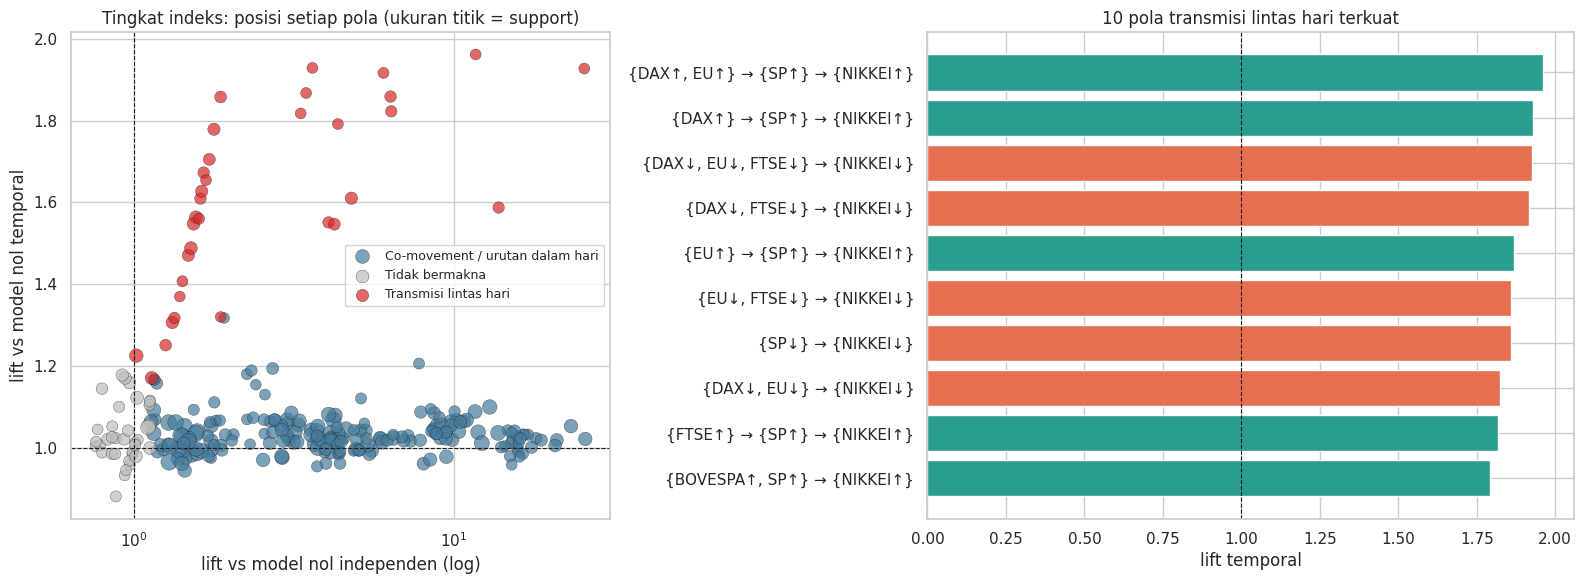

In [26]:
def plot_spm(res, title):
    fig, axes = plt.subplots(1, 2, figsize=(16, 6), gridspec_kw={'width_ratios': [1, 1.2]})
    pal = {'Transmisi lintas hari': '#d62828', 'Co-movement / urutan dalam hari': '#457b9d', 'Tidak bermakna': '#bdbdbd'}
    for k, d in res.groupby('kategori'):
        axes[0].scatter(d['lift_ind'], d['lift_tmp'], s=d['support'] * 300, alpha=.7, color=pal[k], label=k, edgecolor='k', lw=.3)
    axes[0].axhline(1, ls='--', c='k', lw=.8); axes[0].axvline(1, ls='--', c='k', lw=.8)
    axes[0].set_xscale('log'); axes[0].set_xlabel('lift vs model nol independen (log)')
    axes[0].set_ylabel('lift vs model nol temporal'); axes[0].legend(fontsize=9)
    axes[0].set_title(f'{title}: posisi setiap pola (ukuran titik = support)')
    top = res[res['kategori'] == 'Transmisi lintas hari'].nlargest(10, 'lift_tmp').iloc[::-1]
    axes[1].barh(top['pola'], top['lift_tmp'], color=['#e76f51' if '↓' in p else '#2a9d8f' for p in top['pola']])
    axes[1].axvline(1, ls='--', c='k', lw=.8)
    axes[1].set_xlabel('lift temporal'); axes[1].set_title('10 pola transmisi lintas hari terkuat')
    plt.tight_layout(); plt.show()

plot_spm(spm_idx, 'Tingkat indeks')

### 8.5 Pola sekuensial antarwilayah

,Down,Flat,Up
ASIA,0.250,0.483,0.267
TURKI,0.218,0.461,0.321
EROPA,0.237,0.483,0.280
AMERIKA,0.205,0.537,0.257
EM,0.239,0.472,0.289


[wilayah] pola frekuen: 77 | pola >= 2 elemen yang diuji: 63


,jumlah pola
kategori,
Co-movement / urutan dalam hari,31
Transmisi lintas hari,16
Tidak bermakna,16


Seluruh pola antarwilayah yang bermakna secara temporal:


,pola,support,lift_ind,q_ind,lift_tmp,q_tmp,kategori
40,{EROPA↓} → {AMERIKA↓} → {ASIA↓},0.200,5.060,0.008,2.244,0.022,Transmisi lintas hari
0,{AMERIKA↓} → {ASIA↓},0.247,1.886,0.008,1.894,0.022,Transmisi lintas hari
41,{EROPA↓} → {ASIA↓},0.260,1.736,0.008,1.751,0.022,Transmisi lintas hari
1,{AMERIKA↓} → {EM↓},0.204,1.626,0.008,1.629,0.022,Transmisi lintas hari
54,{TURKI↓} → {ASIA↓},0.217,1.543,0.008,1.585,0.022,Transmisi lintas hari
2,{AMERIKA↑} → {ASIA↑},0.268,1.574,0.008,1.584,0.022,Transmisi lintas hari
48,{EROPA↑} → {ASIA↑},0.268,1.459,0.008,1.461,0.022,Transmisi lintas hari
31,{EM↓} → {ASIA↓},0.212,1.400,0.008,1.409,0.022,Transmisi lintas hari
14,"{ASIA↓} → {EROPA↑, TURKI↑}",0.204,1.958,0.008,1.404,0.022,Transmisi lintas hari
17,{ASIA↓} → {TURKI↑} → {EM↑},0.200,1.389,0.008,1.381,0.022,Transmisi lintas hari


Pola co-movement antarwilayah terkuat:


,pola,support,lift_ind,q_ind,lift_tmp,q_tmp,kategori
36,"{EROPA↓, TURKI↓} → {AMERIKA↓, EM↓}",0.204,14.690,0.008,0.990,0.819,Co-movement / urutan dalam hari
44,"{EROPA↑, TURKI↑} → {AMERIKA↑, EM↑}",0.283,7.590,0.008,1.039,0.369,Co-movement / urutan dalam hari
39,"{EROPA↓} → {AMERIKA↓, EM↓}",0.270,4.829,0.008,0.938,0.990,Co-movement / urutan dalam hari
37,"{EROPA↓, TURKI↓} → {EM↓}",0.268,4.430,0.008,0.993,0.834,Co-movement / urutan dalam hari
35,"{EROPA↓, TURKI↓} → {AMERIKA↓}",0.240,4.424,0.008,0.966,0.967,Co-movement / urutan dalam hari
52,"{TURKI↓} → {AMERIKA↓, EM↓}",0.230,4.372,0.008,0.977,0.892,Co-movement / urutan dalam hari


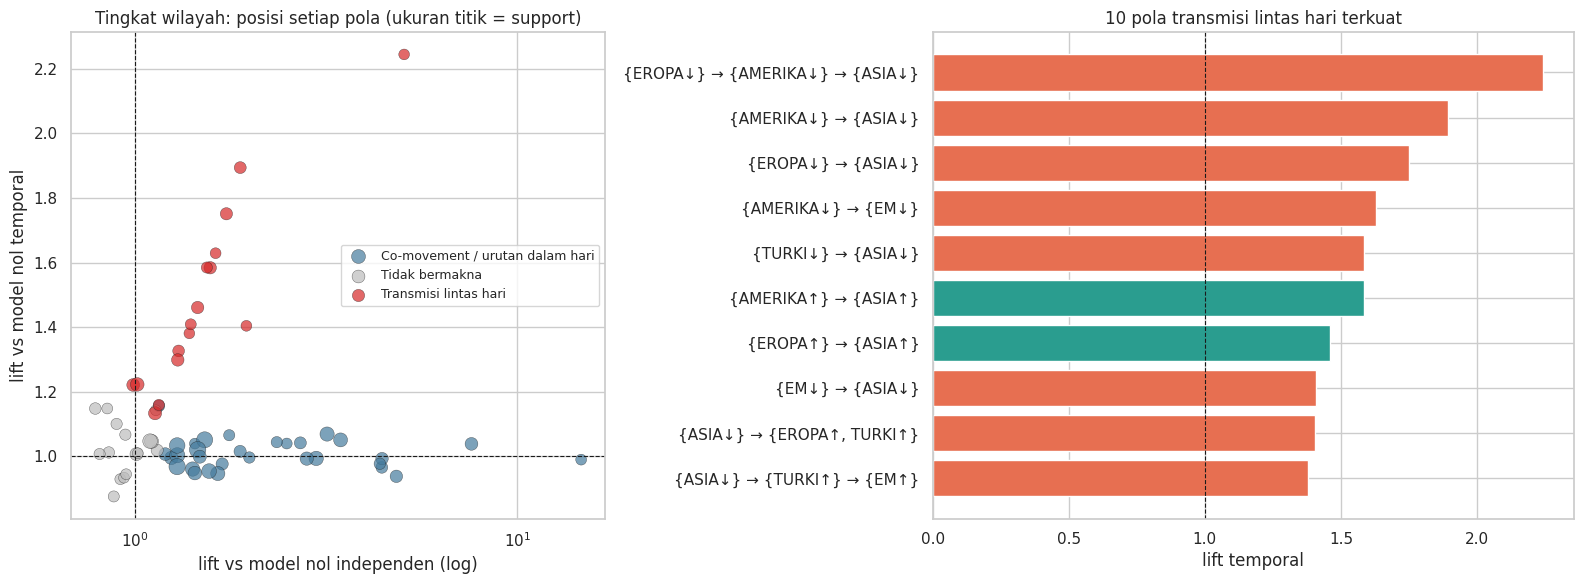

In [27]:
display(reg_states.apply(lambda s: s.value_counts(normalize=True)).T[['Down', 'Flat', 'Up']].round(3))
spm_reg = run_spm(reg_states, SESS_REG, 'wilayah')
display(spm_reg['kategori'].value_counts().to_frame('jumlah pola'))
print('Seluruh pola antarwilayah yang bermakna secara temporal:')
display(spm_reg[spm_reg['kategori'] == 'Transmisi lintas hari'].sort_values('lift_tmp', ascending=False)[SPM_SHOW].round(3))
print('Pola co-movement antarwilayah terkuat:')
display(spm_reg[spm_reg['kategori'] == 'Co-movement / urutan dalam hari'].nlargest(6, 'lift_ind')[SPM_SHOW].round(3))
plot_spm(spm_reg, 'Tingkat wilayah')

### 8.6 Aturan penyebaran sentimen antarwilayah (sequential rule berjeda satu langkah)
Pola PrefixSpan menunjukkan *apa* yang sering berurutan, tetapi belum menjawab *seberapa besar* peluang sentimen berpindah dari wilayah A ke wilayah B. Untuk itu setiap pasangan wilayah diubah menjadi aturan sekuensial `A(s) ⇒ B(s) pada sesi berikutnya yang tersedia bagi B`:

* Jika B tutup setelah A pada hari yang sama, B diambil pada hari yang sama (jeda 0 hari), misalnya ASIA → TURKI.
* Jika B tutup lebih awal atau bersamaan, B diambil pada hari berikutnya (jeda 1 hari), misalnya AMERIKA → ASIA dan AMERIKA → TURKI.

Confidence = P(B searah dengan A | A bergerak), lift = confidence / P(B bergerak ke arah itu). Signifikansi diuji dengan uji binomial satu sisi dan dikoreksi BH. Wilayah yang tutup pada sesi yang sama (TURKI dan EROPA, AMERIKA dan EM) tidak dipasangkan karena urutannya tidak dapat ditentukan.

In [28]:
SESSION_OF = {r: i for i, g in enumerate(SESS_REG) for r in g}

def spillover(rs):
    rows = []
    for A in SESSION_OF:
        for B in SESSION_OF:
            if SESSION_OF[A] == SESSION_OF[B]:
                continue
            lag = 0 if SESSION_OF[B] > SESSION_OF[A] else 1
            a, b = rs[A].values[:len(rs) - lag], rs[B].values[lag:]
            for s in ['Up', 'Down']:
                m = a == s
                k, n, base = int((b[m] == s).sum()), int(m.sum()), (b == s).mean()
                rows.append(dict(asal=A, tujuan=B, jeda_hari=lag, arah=s, n_kejadian=n, confidence=k / n,
                                 base_rate=base, lift=(k / n) / base,
                                 p_value=binomtest(k, n, base, alternative='greater').pvalue))
    out = pd.DataFrame(rows)
    out['q_value'] = bh_adjust(out['p_value'])
    out['signifikan'] = out['q_value'] < ALPHA
    return out

spill = spillover(reg_states)
display(spill.sort_values(['arah', 'lift'], ascending=[True, False]).round(3))

,asal,tujuan,jeda_hari,arah,n_kejadian,confidence,base_rate,lift,p_value,q_value,signifikan
17,EROPA,AMERIKA,0,Down,127,0.567,0.205,2.762,0.000,0.000,True
19,EROPA,EM,0,Down,127,0.606,0.239,2.539,0.000,0.000,True
21,AMERIKA,ASIA,1,Down,110,0.600,0.250,2.396,0.000,0.000,True
13,TURKI,EM,0,Down,117,0.538,0.239,2.255,0.000,0.000,True
15,EROPA,ASIA,1,Down,127,0.543,0.250,2.169,0.000,0.000,True
11,TURKI,AMERIKA,0,Down,117,0.444,0.205,2.166,0.000,0.000,True
7,ASIA,EM,0,Down,134,0.515,0.239,2.156,0.000,0.000,True
9,TURKI,ASIA,1,Down,117,0.487,0.250,1.945,0.000,0.000,True
25,AMERIKA,EROPA,1,Down,110,0.427,0.237,1.800,0.000,0.000,True
23,AMERIKA,TURKI,1,Down,110,0.364,0.219,1.663,0.000,0.001,True


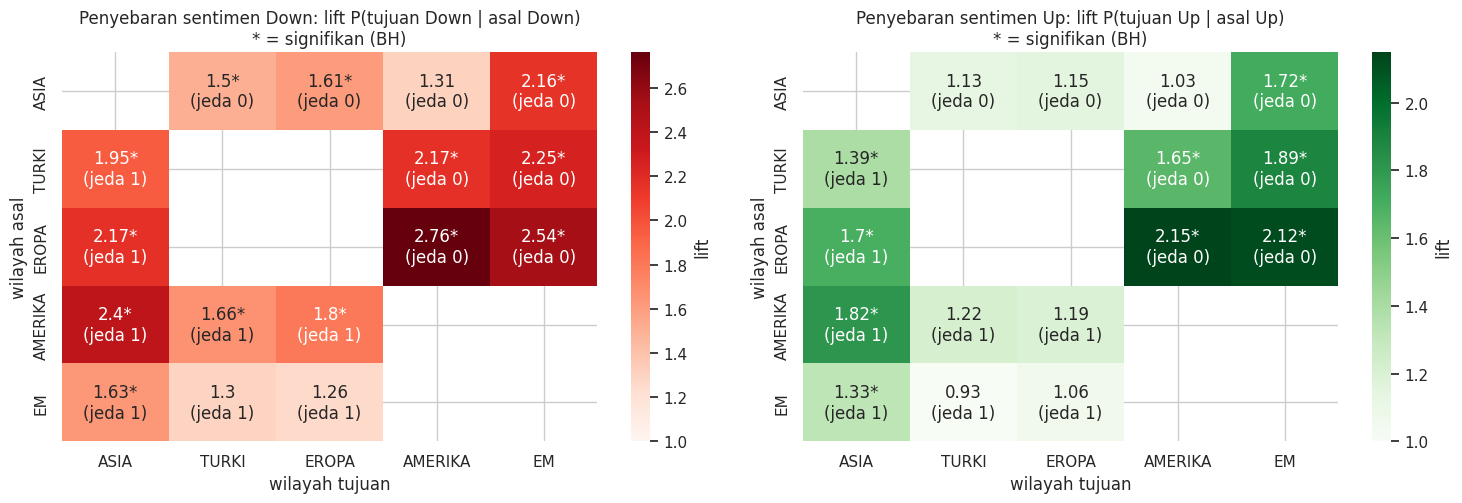

In [29]:
order_reg = ['ASIA', 'TURKI', 'EROPA', 'AMERIKA', 'EM']
fig, axes = plt.subplots(1, 2, figsize=(15, 5.2))
for ax, s, cmap in [(axes[0], 'Down', 'Reds'), (axes[1], 'Up', 'Greens')]:
    d = spill[spill['arah'] == s]
    mat = d.pivot(index='asal', columns='tujuan', values='lift').reindex(index=order_reg, columns=order_reg)
    sg = d.pivot(index='asal', columns='tujuan', values='signifikan').reindex(index=order_reg, columns=order_reg)
    jd = d.pivot(index='asal', columns='tujuan', values='jeda_hari').reindex(index=order_reg, columns=order_reg)
    ann = mat.round(2).astype(str) + np.where(sg.fillna(False).astype(bool), '*', '') + '\n(jeda ' + jd.astype('Int64').astype(str) + ')'
    sns.heatmap(mat, annot=ann.where(mat.notna(), ''), fmt='', cmap=cmap, vmin=1, ax=ax, cbar_kws={'label': 'lift'})
    ax.set_title(f'Penyebaran sentimen {s}: lift P(tujuan {s} | asal {s})\n* = signifikan (BH)')
    ax.set_xlabel('wilayah tujuan'); ax.set_ylabel('wilayah asal')
plt.tight_layout(); plt.show()

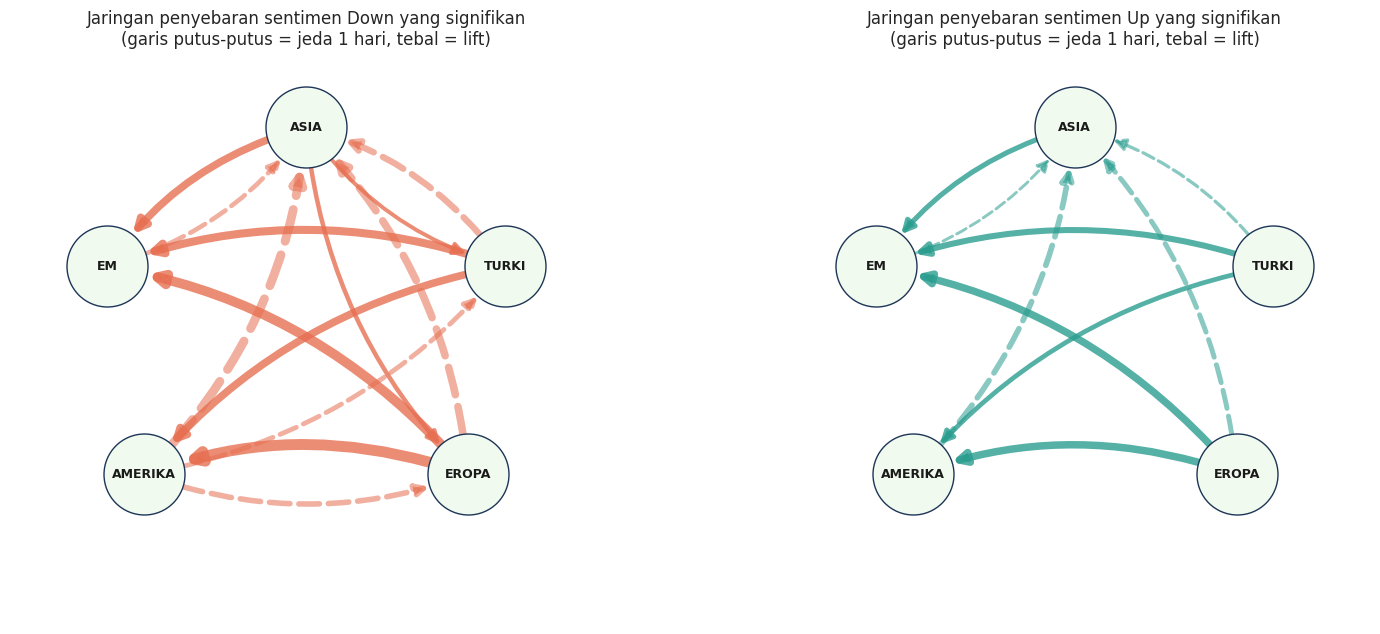

Aturan penyebaran menuju TURKI (ISE):


,asal,tujuan,jeda_hari,arah,n_kejadian,confidence,base_rate,lift,p_value,q_value,signifikan
23,AMERIKA,TURKI,1,Down,110,0.364,0.219,1.663,0.000,0.001,True
1,ASIA,TURKI,0,Down,134,0.328,0.218,1.504,0.002,0.003,True
29,EM,TURKI,1,Down,127,0.283,0.219,1.296,0.052,0.066,False
22,AMERIKA,TURKI,1,Up,138,0.391,0.320,1.224,0.045,0.062,False
0,ASIA,TURKI,0,Up,143,0.364,0.321,1.133,0.157,0.174,False
28,EM,TURKI,1,Up,155,0.297,0.320,0.929,0.755,0.755,False


Aturan penyebaran yang berasal dari TURKI (ISE):


,asal,tujuan,jeda_hari,arah,n_kejadian,confidence,base_rate,lift,p_value,q_value,signifikan
13,TURKI,EM,0,Down,117,0.538,0.239,2.255,0.000,0.000,True
11,TURKI,AMERIKA,0,Down,117,0.444,0.205,2.166,0.000,0.000,True
9,TURKI,ASIA,1,Down,117,0.487,0.250,1.945,0.000,0.000,True
12,TURKI,EM,0,Up,172,0.547,0.289,1.890,0.000,0.000,True
10,TURKI,AMERIKA,0,Up,172,0.424,0.257,1.648,0.000,0.000,True
8,TURKI,ASIA,1,Up,172,0.372,0.267,1.392,0.002,0.003,True


In [30]:
# node disusun melingkar searah urutan jam penutupan: ASIA → TURKI/EROPA → AMERIKA/EM → kembali ke ASIA
ang = {'ASIA': 90, 'TURKI': 20, 'EROPA': -40, 'AMERIKA': -140, 'EM': 160}
pos = {k: (np.cos(np.radians(a)), np.sin(np.radians(a))) for k, a in ang.items()}
fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))
for ax, s in zip(axes, ['Down', 'Up']):
    d = spill[(spill['arah'] == s) & spill['signifikan']]
    G = nx.DiGraph()
    G.add_nodes_from(pos)
    nx.draw_networkx_nodes(G, pos, ax=ax, node_size=3400, node_color='#f1faee', edgecolors='#1d3557')
    nx.draw_networkx_labels(G, pos, ax=ax, font_size=9, font_weight='bold')
    for _, r in d.iterrows():
        rad = 0.18
        nx.draw_networkx_edges(nx.DiGraph([(r['asal'], r['tujuan'])]), pos, ax=ax, width=(r['lift'] - 1) * 4 + .8,
                               edge_color=COLOR[s], alpha=.8 if r['jeda_hari'] == 0 else .55, arrowsize=18,
                               style='solid' if r['jeda_hari'] == 0 else 'dashed',
                               connectionstyle=f'arc3,rad={rad}', node_size=3400)
    ax.set_title(f'Jaringan penyebaran sentimen {s} yang signifikan\n(garis putus-putus = jeda 1 hari, tebal = lift)')
    ax.axis('off'); ax.set_aspect('equal'); ax.set_xlim(-1.4, 1.4); ax.set_ylim(-1.35, 1.35)
plt.tight_layout(); plt.show()

print('Aturan penyebaran menuju TURKI (ISE):')
display(spill[spill['tujuan'] == 'TURKI'].sort_values('lift', ascending=False).round(3))
print('Aturan penyebaran yang berasal dari TURKI (ISE):')
display(spill[spill['asal'] == 'TURKI'].sort_values('lift', ascending=False).round(3))


### 8.7 Interpretasi SPM
**1. Sebagian besar pola yang "sering" hanyalah co-movement harian.** Dari 270 pola antarindeks, 201 hanya signifikan terhadap model nol independen dan lift temporalnya sekitar 1. Contohnya `{DAX↓, EU↓, FTSE↓} → {SP↓}` (support 31,6%, lift independen 25,8, lift temporal 1,02): urutannya tampak seperti Eropa memimpin Amerika, padahal itu kejadian pada hari yang sama yang terlihat berurutan karena jam tutup berbeda. Jika hanya memakai support, pola semacam ini akan salah dibaca sebagai transmisi.

**2. Transmisi lintas hari mengalir dari Barat ke Asia.** Sebanyak 26 dari 33 pola transmisi lintas hari berakhir di NIKKEI, dan sebagian besar sisanya justru dimulai dari NIKKEI. Contohnya `{DAX↑} → {SP↑} → {NIKKEI↑}` (support 21%, lift temporal 1,93) dan `{SP↓} → {NIKKEI↓}` (24,3%, lift temporal 1,86). Tokyo adalah pasar pertama yang buka setelah New York tutup, sehingga Tokyo menyerap sentimen Eropa dan Amerika dari hari sebelumnya. Pada tingkat wilayah, pola temporal terkuat adalah rantai lengkap `{EROPA↓} → {AMERIKA↓} → {ASIA↓}` (support 20%, lift temporal 2,24): tekanan jual bergerak mengikuti matahari dari Eropa ke Amerika lalu ke Asia keesokan harinya.

**3. Posisi ISE.** ISE bergerak sebagai bagian dari blok Eropa. Pola temporal yang memuat ISE adalah `{ISE↓} → {NIKKEI↓}` (lift temporal 1,56) dan `{ISE↑} → {NIKKEI↑}` (1,31), yaitu ISE ikut menjadi bagian sentimen sesi Eropa yang kemudian terbawa ke Asia. Ada juga pola pembalikan `{NIKKEI↓} → {ISE↑}` dan `{ASIA↓} → {EROPA↑, TURKI↑}` yang sejalan dengan aturan lag `NIKKEI(t-1)↓ ⇒ ISE↑`.

**4. Aturan penyebaran antarwilayah (Bagian 8.6).**
* Jalur terkuat ada di dalam hari yang sama: EROPA → AMERIKA (Down: confidence 56,7%, lift 2,76; Up: 55,3%, lift 2,15).
* Jalur semalam terkuat: AMERIKA(t)↓ → ASIA(t+1)↓, confidence 60% vs base rate 25% (lift 2,40).
* **Jalur yang masuk ke TURKI hanya signifikan untuk arah turun:** AMERIKA(t-1)↓ → TURKI↓ (36,4% vs 21,9%, lift 1,66) dan ASIA(t)↓ → TURKI(t)↓ (32,8%, lift 1,50). Jalur naik dari Amerika (lift 1,22) dan Asia (1,13) tidak signifikan.
* Dari TURKI, sentimen ikut terbawa ke AMERIKA pada hari yang sama (Down lift 2,17) dan ke ASIA keesokan harinya (1,95). Karena Istanbul dan Eropa tutup pada sesi yang sama, data ini tidak bisa memisahkan apakah ISE ikut menyebarkan sentimen atau sekadar bergerak bersama Eropa.
* **Asimetri:** 13 dari 16 jalur Down signifikan, sedangkan Up hanya 9 dari 16, dan lift Down hampir selalu lebih besar (misalnya AMERIKA → ASIA: 2,40 vs 1,82). Sentimen negatif menyebar lebih luas dan lebih kuat daripada sentimen positif.


## 9. Uji Sensitivitas Ambang Diskretisasi
Pilihan K = 0,5 bersifat subjektif, sehingga seluruh analisis inti diulang untuk K = 0,25 dan K = 0,75. Temuan yang dianggap kokoh adalah temuan yang arahnya tidak berubah ketika K diganti.

In [31]:
rows = []
for k in [0.25, 0.5, 0.75]:
    st_k = discretize(ret, sigma, k)
    rs_k = mine_rules(build_same(st_k), TARGETS, ARM_SAME_MINSUP, ARM_SAME_MAXLEN)
    rl_k = mine_rules(build_lag(st_k), TARGETS, ARM_LAG_MINSUP, ARM_LAG_MAXLEN)
    sp_k = spillover(discretize(regions, regions.std(), k)).set_index(['asal', 'tujuan', 'arah'])
    row = {'K': k}
    for t in ['ISE↑', 'ISE↓']:
        s_sig = rs_k[rs_k['signifikan'] & (rs_k['target'] == t)]
        l_sig = rl_k[rl_k['signifikan'] & (rl_k['target'] == t)]
        row[f'ARM sama: sig {t}'] = len(s_sig)
        row[f'ARM sama: aturan terkuat {t}'] = s_sig.nlargest(1, 'lift')['rule'].str.cat() if len(s_sig) else '-'
        row[f'ARM lag: sig {t}'] = len(l_sig)
        row[f'ARM lag: aturan terkuat {t}'] = (l_sig.nlargest(1, 'lift')['rule'].str.cat() + f" (lift {l_sig['lift'].max():.2f})") if len(l_sig) else '-'
    for rule, tgt in [('BOVESPA(t-1)↓', 'ISE↓'), ('SP(t-1)↓', 'ISE↓'), ('NIKKEI(t-1)↓', 'ISE↑')]:
        r = rl_k[(rl_k['rule'] == rule) & (rl_k['target'] == tgt)]
        row[f'lag {rule} ⇒ {tgt}'] = f"{r['lift'].iloc[0]:.2f}{'*' if r['signifikan'].iloc[0] else ''}" if len(r) else '-'
    for (a, b, s) in [('AMERIKA', 'ASIA', 'Down'), ('AMERIKA', 'TURKI', 'Down'), ('AMERIKA', 'TURKI', 'Up'),
                      ('ASIA', 'TURKI', 'Down'), ('EROPA', 'AMERIKA', 'Down')]:
        r = sp_k.loc[(a, b, s)]
        row[f'lift {a}→{b} {s}'] = f"{r['lift']:.2f}{'*' if r['signifikan'] else ''}"
    rows.append(row)
sens = pd.DataFrame(rows).set_index('K').T
sens

K,0.25,0.50,0.75
ARM sama: sig ISE↑,33,26,24
ARM sama: aturan terkuat ISE↑,BOVESPA↑ + EM↑ + EU↑,EM↑ + EU↑ + SP↑,BOVESPA↑ + EM↑ + FTSE↑
ARM lag: sig ISE↑,4,2,0
ARM lag: aturan terkuat ISE↑,BOVESPA(t-1)↑ + EM(t-1)↓ (lift 1.83),BOVESPA(t-1)↑ + NIKKEI(t-1)↓ (lift 1.83),-
ARM sama: sig ISE↓,48,27,18
ARM sama: aturan terkuat ISE↓,DAX↓ + EM↓ + SP↓,BOVESPA↓ + DAX↓ + EM↓,DAX↓ + EM↓
ARM lag: sig ISE↓,5,4,4
ARM lag: aturan terkuat ISE↓,BOVESPA(t-1)↓ + DAX(t-1)↑ (lift 1.90),FTSE(t-1)↓ + SP(t-1)↓ (lift 1.73),DAX(t-1)↓ + SP(t-1)↓ (lift 2.00)
lag BOVESPA(t-1)↓ ⇒ ISE↓,1.41*,1.60*,1.85*
lag SP(t-1)↓ ⇒ ISE↓,1.31*,1.54*,1.76*



**Interpretasi uji sensitivitas**
* **ARM hari yang sama kokoh.** Jumlah aturan signifikan berubah (ISE↑: 33/26/24; ISE↓: 48/27/18) karena ambang yang lebih ketat membuat kejadian lebih jarang, tetapi aturan terkuat di setiap K tetap kombinasi Eropa + Amerika + EM yang searah.
* **ARM lag rapuh pada arah naik.** Aturan ISE↑ hilang seluruhnya pada K = 0,75, dan `NIKKEI(t-1)↓ ⇒ ISE↑` hanya signifikan pada K = 0,5. Sebaliknya `BOVESPA(t-1)↓ ⇒ ISE↓` signifikan pada ketiga K, dengan lift naik dari 1,41 ke 1,85 ketika ambang diperketat: makin dalam penurunan BOVESPA kemarin, makin kuat asosiasinya dengan ISE turun hari ini. `SP(t-1)↓ ⇒ ISE↓` juga signifikan di semua K, tetapi tidak stabil antarperiode (Bagian 7.3).
* **Penyebaran sentimen kokoh.** AMERIKA → TURKI Down (1,50 / 1,66 / 1,65) dan ASIA → TURKI Down (1,35 / 1,50 / 1,68) signifikan di semua K. AMERIKA → TURKI Up hanya signifikan pada K = 0,25, sehingga asimetri turun vs naik bukan artefak pemilihan ambang.



## 10. Jawaban Rumusan Masalah

**RM 1. Kombinasi kondisi pasar global apa yang sering terjadi bersamaan dengan naik atau turunnya ISE pada hari yang sama?**

ISE bergerak bersama pasar global ketika pergerakan itu serentak lintas wilayah. Kombinasi terkuat terdiri dari satu indeks Eropa, satu indeks Amerika, dan EM yang searah: `EM↑ + EU↑ + SP↑` diikuti ISE naik pada 81% kejadian (base rate 32%), dan `BOVESPA↓ + DAX↓ + EM↓` diikuti ISE turun pada 74% kejadian (base rate 22%). Secara individual, Eropa (DAX, EU, FTSE) dan EM adalah indikator paling kuat, sedangkan NIKKEI paling lemah. Asosiasi ke arah turun lebih kuat (lift sekitar 3) daripada ke arah naik (lift sekitar 2,5). Aturan-aturan ini stabil antarperiode dan antarambang diskretisasi.

**RM 2. Apakah kondisi pasar global pada hari sebelumnya dapat menjadi petunjuk arah ISE hari ini?**

Bisa, tetapi lemah dan hanya untuk sebagian kecil kondisi. Dari 102 aturan lag, 6 yang signifikan, dan hanya `BOVESPA(t-1)↓ ⇒ ISE↓` yang lolos semua pemeriksaan (signifikan di tiga ambang, stabil di dua subperiode). Aturan ini menaikkan peluang ISE turun dari sekitar 22% menjadi sekitar 35%. Aturan berbasis SP signifikan di dalam sampel tetapi gagal pada periode uji, dan sinyal untuk arah naik tidak kokoh. Kesimpulannya, informasi hari sebelumnya berguna sebagai penanda kenaikan risiko penurunan ISE, tetapi tidak cukup untuk memprediksi arah ISE secara andal. Kebersamaan pergerakan pada hari yang sama (RM 1) jauh lebih kuat daripada sinyal hari sebelumnya.

**RM 3. Urutan pergerakan antarpasar seperti apa yang sering terjadi, dan bagaimana sentimen menyebar antarwilayah?**

Sebagian besar urutan yang sering muncul ternyata hanya *co-movement* harian yang terlihat berurutan karena perbedaan jam tutup. Setelah dipisahkan dengan model nol temporal, pola penyebaran yang nyata mengikuti arah jam perdagangan: **Eropa → Amerika pada hari yang sama, lalu Amerika → Asia keesokan harinya**, dengan rantai `{EROPA↓} → {AMERIKA↓} → {ASIA↓}` sebagai pola temporal terkuat. ISE bergerak sebagai bagian dari blok Eropa. Sentimen yang masuk ke ISE berasal dari Amerika hari sebelumnya dan dari Asia pada pagi hari yang sama, tetapi **hanya sentimen negatif** yang tersalur secara signifikan dan konsisten di semua ambang. Secara umum sentimen negatif menyebar lebih luas (13 dari 16 jalur) dan lebih kuat daripada sentimen positif (9 dari 16 jalur).

### Keterbatasan
* Data hanya 536 hari pada periode pemulihan setelah krisis 2008. Beberapa aturan lag didukung kurang dari 50 hari, sehingga temuan perlu diuji ulang pada periode lain.
* Waktu penutupan per sesi adalah perkiraan, dan Istanbul tutup bersamaan dengan Eropa. Arah pengaruh antara ISE dan Eropa tidak bisa ditentukan dari data harian.
* Seluruh temuan bersifat asosiatif. ARM dan SPM tidak membuktikan hubungan sebab-akibat.
* Diskretisasi menghilangkan informasi besaran return. Pengaruh pilihan ambang sudah diuji pada Bagian 9, tetapi hanya untuk tiga nilai K.
* Model nol temporal mengacak urutan hari, sehingga juga menghilangkan pengelompokan volatilitas (hari-hari buruk cenderung berdekatan). Sebagian pola lintas hari mungkin mencerminkan periode pasar yang bergejolak, bukan murni transmisi arah. Aturan penyebaran berjeda satu langkah pada Bagian 8.6 lebih spesifik terhadap masalah ini karena hanya membandingkan sesi yang berurutan langsung.


In [32]:
# =====================================================================
# TABEL RINGKASAN: support, confidence, lift, dan jumlah kejadian
# untuk semua metode (ARM hari yang sama, ARM lag, SPM, aturan penyebaran)
# =====================================================================
HANYA_SIGNIFIKAN = True    # ubah ke False untuk menampilkan semua aturan/pola

# ---------- 1. ARM (hari yang sama dan lag) ----------
def ringkas_arm(rules, n_transaksi, metode):
    d = rules.copy()
    return pd.DataFrame({
        'metode': metode,
        'aturan / pola': d['rule'] + ' ⇒ ' + d['target'],
        'n_antecedent': (d['support'] / d['confidence'] * n_transaksi).round().astype(int),
        'n_kejadian': d['n_hari'],
        'n_total': n_transaksi,
        'support': d['support'],
        'confidence': d['confidence'],
        'lift': d['lift'],
        'signifikan': d['signifikan'],
    })

tab_same = ringkas_arm(rules_same, len(X_same), 'ARM hari yang sama')
tab_lag = ringkas_arm(rules_lag, len(X_lag), 'ARM lag t-1')

# ---------- 2. SPM (pola <α1..αk-1> dibaca sebagai aturan ⇒ αk) ----------
def ringkas_spm(res, st, sessions, metode):
    db = build_windows(st, sessions)
    vocab = {f'{c}_{s}': i for i, (c, s) in enumerate(
        (c, s) for g in sessions for c in g for s in ['Up', 'Down'])}
    E, n = encode(db, vocab), len(db)
    sup_prefix = np.array([support_vec(E, p[:-1], vocab) for p in res['raw']])
    sup_akhir = np.array([support_vec(E, [p[-1]], vocab) for p in res['raw']])
    conf = res['support'].values / sup_prefix
    return pd.DataFrame({
        'metode': metode,
        'aturan / pola': res['pola'].values,
        'n_antecedent': (sup_prefix * n).round().astype(int),
        'n_kejadian': (res['support'].values * n).round().astype(int),
        'n_total': n,
        'support': res['support'].values,
        'confidence': conf,
        'lift': conf / sup_akhir,
        'signifikan': (res['kategori'] != 'Tidak bermakna').values,
        'kategori SPM': res['kategori'].values,
        'lift_temporal': res['lift_tmp'].values,
    })

tab_spm_idx = ringkas_spm(spm_idx, states, SESS_IDX, 'SPM antarindeks')
tab_spm_reg = ringkas_spm(spm_reg, reg_states, SESS_REG, 'SPM antarwilayah')

# ---------- 3. Aturan penyebaran antarwilayah ----------
d = spill.copy()
n_total = len(reg_states) - d['jeda_hari']
n_bersama = (d['confidence'] * d['n_kejadian']).round().astype(int)
panah = {'Up': '↑', 'Down': '↓'}
tab_spill = pd.DataFrame({
    'metode': 'Penyebaran antarwilayah',
    'aturan / pola': d['asal'] + d['arah'].map(panah) + ' ⇒ ' + d['tujuan'] + d['arah'].map(panah)
                     + ' (jeda ' + d['jeda_hari'].astype(str) + ' hari)',
    'n_antecedent': d['n_kejadian'],
    'n_kejadian': n_bersama,
    'n_total': n_total,
    'support': n_bersama / n_total,
    'confidence': d['confidence'],
    'lift': d['lift'],
    'signifikan': d['signifikan'],
})

# ---------- 4. Gabungkan ----------
tabel_lengkap = pd.concat([tab_same, tab_lag, tab_spm_idx, tab_spm_reg, tab_spill], ignore_index=True)
if HANYA_SIGNIFIKAN:
    tabel_lengkap = tabel_lengkap[tabel_lengkap['signifikan']]
tabel_lengkap = (tabel_lengkap
                 .sort_values(['metode', 'lift'], ascending=[True, False])
                 .reset_index(drop=True))

print('Jumlah baris per metode:')
display(tabel_lengkap['metode'].value_counts().to_frame('jumlah'))

pd.set_option('display.max_rows', 500)
display(tabel_lengkap.round(4))

# simpan agar bisa dibuka di Excel / ditempel ke laporan
tabel_lengkap.round(4).to_csv(f'{OUTPUT_DIR}/tabel_ringkasan_arm_spm.csv', index=False)
print(f'Tersimpan: {OUTPUT_DIR}/tabel_ringkasan_arm_spm.csv')

Jumlah baris per metode:


,jumlah
metode,
SPM antarindeks,234
ARM hari yang sama,53
SPM antarwilayah,47
Penyebaran antarwilayah,22
ARM lag t-1,6


,metode,aturan / pola,n_antecedent,n_kejadian,n_total,support,confidence,lift,signifikan,kategori SPM,lift_temporal
0,ARM hari yang sama,BOVESPA↓ + DAX↓ + EM↓ ⇒ ISE↓,46,34,536,0.0634,0.7391,3.3861,True,NaN,NaN
1,ARM hari yang sama,BOVESPA↓ + EM↓ + EU↓ ⇒ ISE↓,48,34,536,0.0634,0.7083,3.2450,True,NaN,NaN
2,ARM hari yang sama,DAX↓ + EM↓ ⇒ ISE↓,71,48,536,0.0896,0.6761,3.0971,True,NaN,NaN
3,ARM hari yang sama,BOVESPA↓ + DAX↓ ⇒ ISE↓,64,43,536,0.0802,0.6719,3.0780,True,NaN,NaN
4,ARM hari yang sama,BOVESPA↓ + EU↓ ⇒ ISE↓,63,42,536,0.0784,0.6667,3.0541,True,NaN,NaN
5,ARM hari yang sama,BOVESPA↓ + EM↓ + FTSE↓ ⇒ ISE↓,47,31,536,0.0578,0.6596,3.0216,True,NaN,NaN
6,ARM hari yang sama,BOVESPA↓ + FTSE↓ + SP↓ ⇒ ISE↓,52,34,536,0.0634,0.6538,2.9954,True,NaN,NaN
7,ARM hari yang sama,EM↓ + EU↓ + SP↓ ⇒ ISE↓,49,32,536,0.0597,0.6531,2.9918,True,NaN,NaN
8,ARM hari yang sama,EM↓ + EU↓ ⇒ ISE↓,76,48,536,0.0896,0.6316,2.8934,True,NaN,NaN
9,ARM hari yang sama,BOVESPA↓ + FTSE↓ ⇒ ISE↓,62,39,536,0.0728,0.6290,2.8817,True,NaN,NaN


Tersimpan: tabel_ringkasan_arm_spm.csv
